# 📱 Smartphone Price — Predictive Analytics
### Random Forest vs Gradient Boosting (end-to-end)

**Goal:** predict a smartphone's **market price (₹)** from its specifications, and compare two ensemble models head-to-head:

| Model | Idea |
|---|---|
| 🌲 **Random Forest** | many deep trees trained in parallel on bootstrap samples, predictions averaged (variance reduction) |
| 🚀 **Gradient Boosting** | shallow trees trained *sequentially*, each one correcting the errors of the previous ones (bias reduction) |

**Workflow**
1. Load & inspect data
2. Exploratory data analysis (EDA) with visualisations
3. Feature engineering & preprocessing pipeline (no data leakage)
4. Baseline models → hyper-parameter tuning (RandomizedSearchCV, 5-fold CV)
5. Test-set evaluation, residual analysis, CV comparison
6. Interpretation: feature importance, permutation importance, partial dependence, learning curves
7. Error analysis by price segment / brand, "under-priced vs over-priced" phones
8. Bonus: price-**segment classification** (Budget / Mid / Upper-mid / Flagship) with the same two algorithms
9. Final comparison, saving models, conclusions

> Only **RandomForest** and **GradientBoosting** (scikit-learn) are used for modelling, as requested.

In [1]:
import warnings, time, joblib, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, cross_validate,
                                     cross_val_score, cross_val_predict, RandomizedSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, label_binarize
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, median_absolute_error,
                             mean_absolute_percentage_error, r2_score, accuracy_score,
                             balanced_accuracy_score, f1_score, matthews_corrcoef,
                             classification_report, ConfusionMatrixDisplay, roc_curve, auc)

# ---- global look & feel
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13})
RF_C, GB_C = "#1f9e89", "#f28e2b"          # fixed colours: RF = teal, GB = orange
RANDOM_STATE = 42
print("Libraries loaded ✔")

Libraries loaded ✔


## 1️⃣ Load the data

In [2]:
candidates = [Path("smartphones_v4.csv"), Path("/mnt/user-data/uploads/smartphones_v4.csv")]
DATA_PATH = next(p for p in candidates if p.exists())
df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}  →  {df.shape[0]} phones × {df.shape[1]} columns")
display(df.head())

Loaded smartphones_v4.csv  →  858 phones × 29 columns


,brand,model,price,rating,is_dual_sim,is_5G,is_irBlaster,is_nfc,is_eSim,processor_name,...,refresh_rate,screen_spec,back_camera,front_camera,no_of_rear,no_of_front,extended_memory_available,extend_upto,os,os_version
0,vivo,Vivo S2 5G,39999,67.0,True,True,False,False,False,Dimensity 7360 Turbo,...,120.0,Punch Hole,50.0,32.0,2,1.0,False,NaN,Android,16.0
1,oneplus,OnePlus N6x,18999,NaN,True,True,False,False,False,Dimensity 6360 Apex,...,120.0,Punch Hole,13.0,5.0,1,1.0,True,2048.0,Android,16.0
2,samsung,Samsung Galaxy F70 Pro 5G,23999,67.0,True,True,False,False,False,Snapdragon 6 Gen3,...,120.0,Punch Hole,50.0,12.0,3,1.0,True,1024.0,Android,16.0
3,poco,Poco M8 Power,24999,63.0,True,True,True,False,False,Snapdragon 4 Gen4,...,120.0,Punch Hole,50.0,8.0,2,1.0,True,1024.0,Android,16.0
4,vivo,Vivo T4 Pro 5G (8GB RAM + 256GB),29999,72.0,True,True,True,False,False,Snapdragon 7 Gen4,...,120.0,Punch Hole,50.0,32.0,3,1.0,False,NaN,Android,15.0


In [3]:
print("=== Data types & non-null counts ===")
df.info()
print("\n=== Numeric summary ===")
display(df.describe().T.round(2))
print("\n=== Duplicates ===")
print("duplicate rows:", df.duplicated().sum(), "| duplicate model names:", df["model"].duplicated().sum())

=== Data types & non-null counts ===
<class 'pandas.DataFrame'>
RangeIndex: 858 entries, 0 to 857
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      858 non-null    str    
 1   model                      858 non-null    str    
 2   price                      858 non-null    int64  
 3   rating                     611 non-null    float64
 4   is_dual_sim                858 non-null    bool   
 5   is_5G                      858 non-null    bool   
 6   is_irBlaster               858 non-null    bool   
 7   is_nfc                     858 non-null    bool   
 8   is_eSim                    858 non-null    bool   
 9   processor_name             852 non-null    str    
 10  core                       853 non-null    float64
 11  processor_speed            802 non-null    float64
 12  ram_size                   856 non-null    float64
 13  internal_memory         

,count,mean,std,min,25%,50%,75%,max
price,858.0,38670.12,35642.55,5700.00,17999.0,27230.0,43999.00,259999.00
rating,611.0,64.13,7.82,50.00,58.0,64.0,70.00,79.00
core,853.0,7.90,0.83,1.00,8.0,8.0,8.00,10.00
processor_speed,802.0,2.69,0.65,0.00,2.4,2.5,3.00,4.74
ram_size,856.0,7.90,3.09,2.00,6.0,8.0,8.00,16.00
internal_memory,858.0,207.37,159.41,0.03,128.0,128.0,256.00,2048.00
battery_capacity,858.0,5689.85,1136.38,2000.00,5000.0,5500.0,6500.00,10001.00
max_chrg_pwr,788.0,49.32,28.48,10.00,25.0,45.0,80.00,150.00
screen_size,858.0,6.69,0.33,3.75,6.6,6.7,6.78,8.09
refresh_rate,858.0,115.63,21.82,60.00,120.0,120.0,120.00,165.00



=== Duplicates ===
duplicate rows: 0 | duplicate model names: 0


## 2️⃣ Exploratory Data Analysis

First, how much data is missing, and what does the target (**price**) look like?

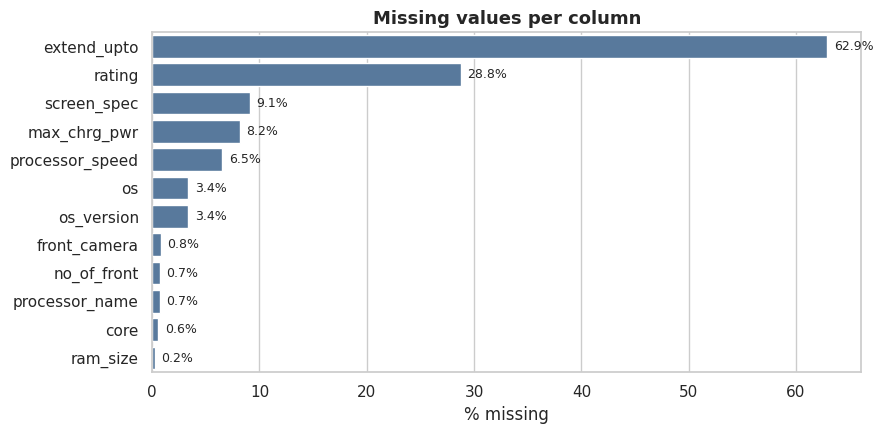

Notes:
 • `extend_upto` is empty when a phone has no card slot → will be filled with 0 (no expandable memory).
 • `rating` is missing for ~29% of phones and is a post-launch popularity score, so it is NOT used as a model input.


In [4]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=miss.values, y=miss.index, color="#4c78a8", ax=ax)
for i, v in enumerate(miss.values):
    ax.text(v + 0.6, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% missing"); ax.set_ylabel("")
ax.set_title("Missing values per column")
plt.tight_layout(); plt.show()

print("Notes:\n • `extend_upto` is empty when a phone has no card slot → will be filled with 0 (no expandable memory)."
      "\n • `rating` is missing for ~29% of phones and is a post-launch popularity score, so it is NOT used as a model input.")

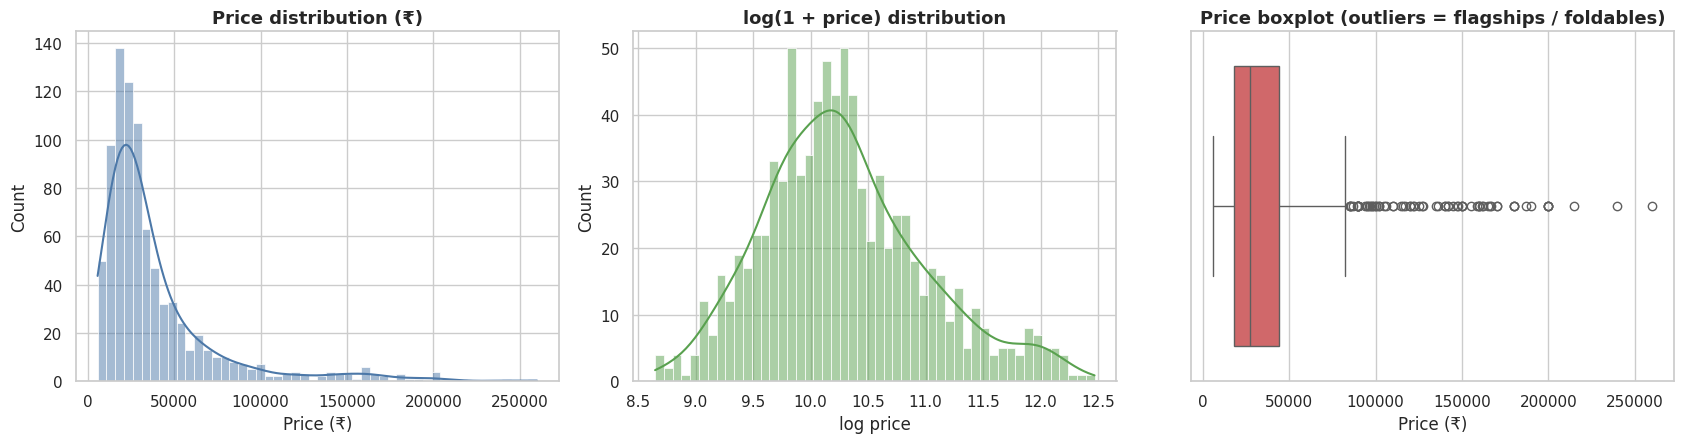

Price  → mean ₹38,670 | median ₹27,230 | min ₹5,700 | max ₹259,999
Skewness raw = 2.63   →   after log = 0.52
Because price is heavily right-skewed, models are trained on log(price) and predictions are converted back to ₹.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.histplot(df["price"], bins=50, kde=True, color="#4c78a8", ax=axes[0])
axes[0].set_title("Price distribution (₹)"); axes[0].set_xlabel("Price (₹)")

sns.histplot(np.log1p(df["price"]), bins=50, kde=True, color="#59a14f", ax=axes[1])
axes[1].set_title("log(1 + price) distribution"); axes[1].set_xlabel("log price")

sns.boxplot(x=df["price"], color="#e15759", ax=axes[2])
axes[2].set_title("Price boxplot (outliers = flagships / foldables)"); axes[2].set_xlabel("Price (₹)")
plt.tight_layout(); plt.show()

print(f"Price  → mean ₹{df.price.mean():,.0f} | median ₹{df.price.median():,.0f} | min ₹{df.price.min():,} | max ₹{df.price.max():,}")
print(f"Skewness raw = {stats.skew(df.price):.2f}   →   after log = {stats.skew(np.log1p(df.price)):.2f}")
print("Because price is heavily right-skewed, models are trained on log(price) and predictions are converted back to ₹.")

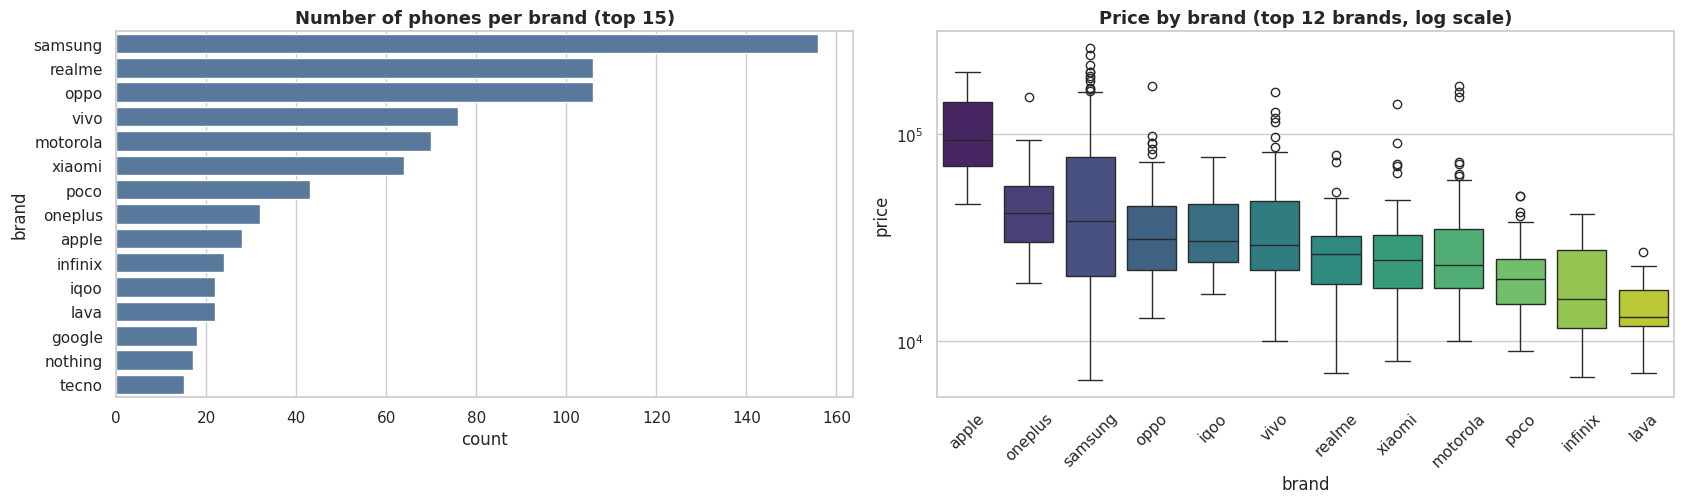

In [6]:
top_brands = df["brand"].value_counts().head(12).index
order = df[df.brand.isin(top_brands)].groupby("brand")["price"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
sns.countplot(data=df, y="brand", order=df["brand"].value_counts().head(15).index, color="#4c78a8", ax=axes[0])
axes[0].set_title("Number of phones per brand (top 15)")

sns.boxplot(data=df[df.brand.isin(top_brands)], x="brand", y="price", order=order, palette="viridis", ax=axes[1])
axes[1].set_yscale("log"); axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("Price by brand (top 12 brands, log scale)")
plt.tight_layout(); plt.show()

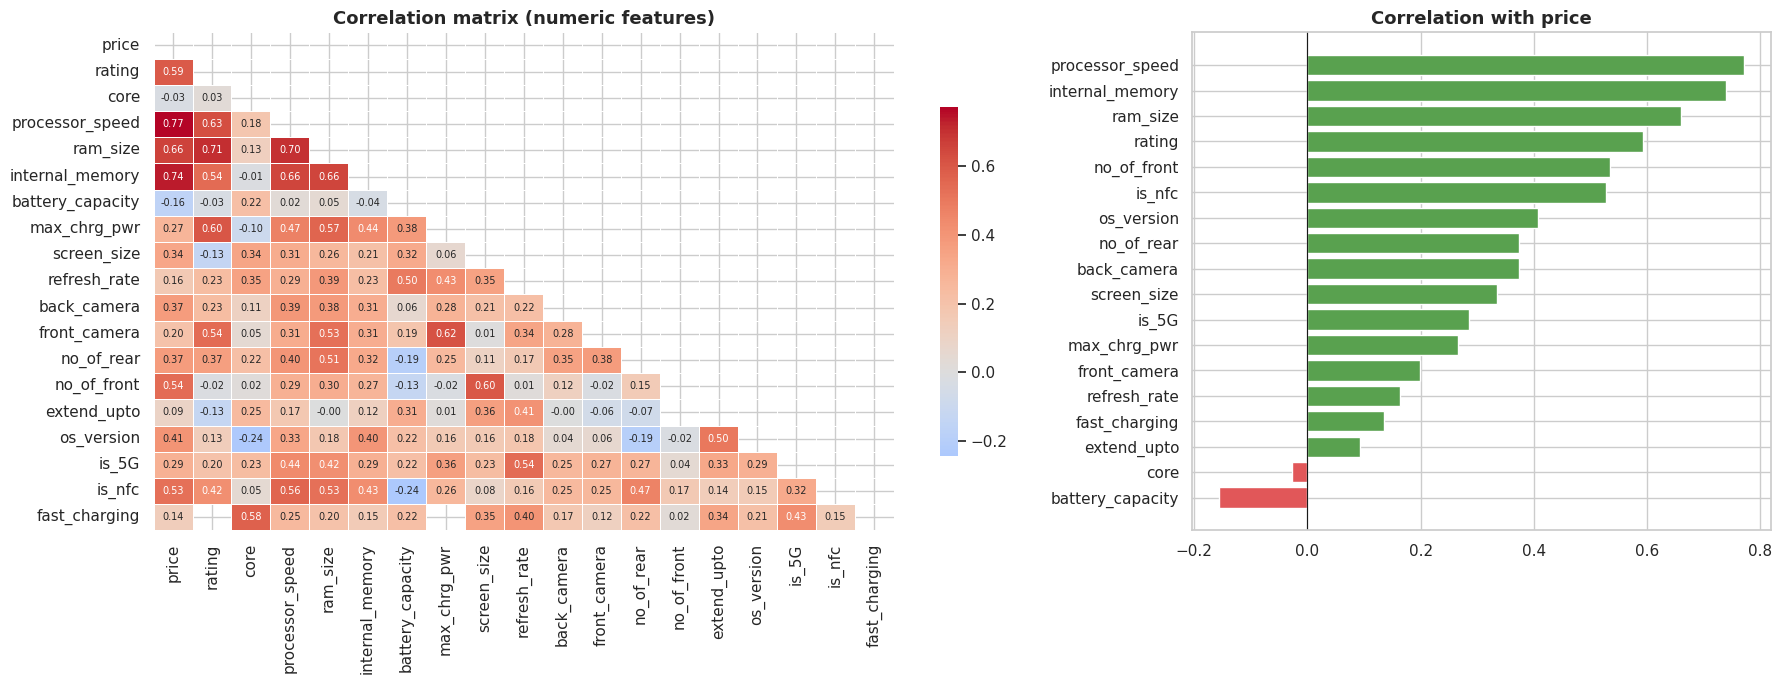

In [7]:
num_cols_eda = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[num_cols_eda + ["is_5G", "is_nfc", "fast_charging"]].astype(float).corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.6, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=.4, cbar_kws={"shrink": .7}, ax=axes[0])
axes[0].set_title("Correlation matrix (numeric features)")

pc = corr["price"].drop("price").sort_values()
axes[1].barh(pc.index, pc.values, color=np.where(pc.values > 0, "#59a14f", "#e15759"))
axes[1].set_title("Correlation with price"); axes[1].axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

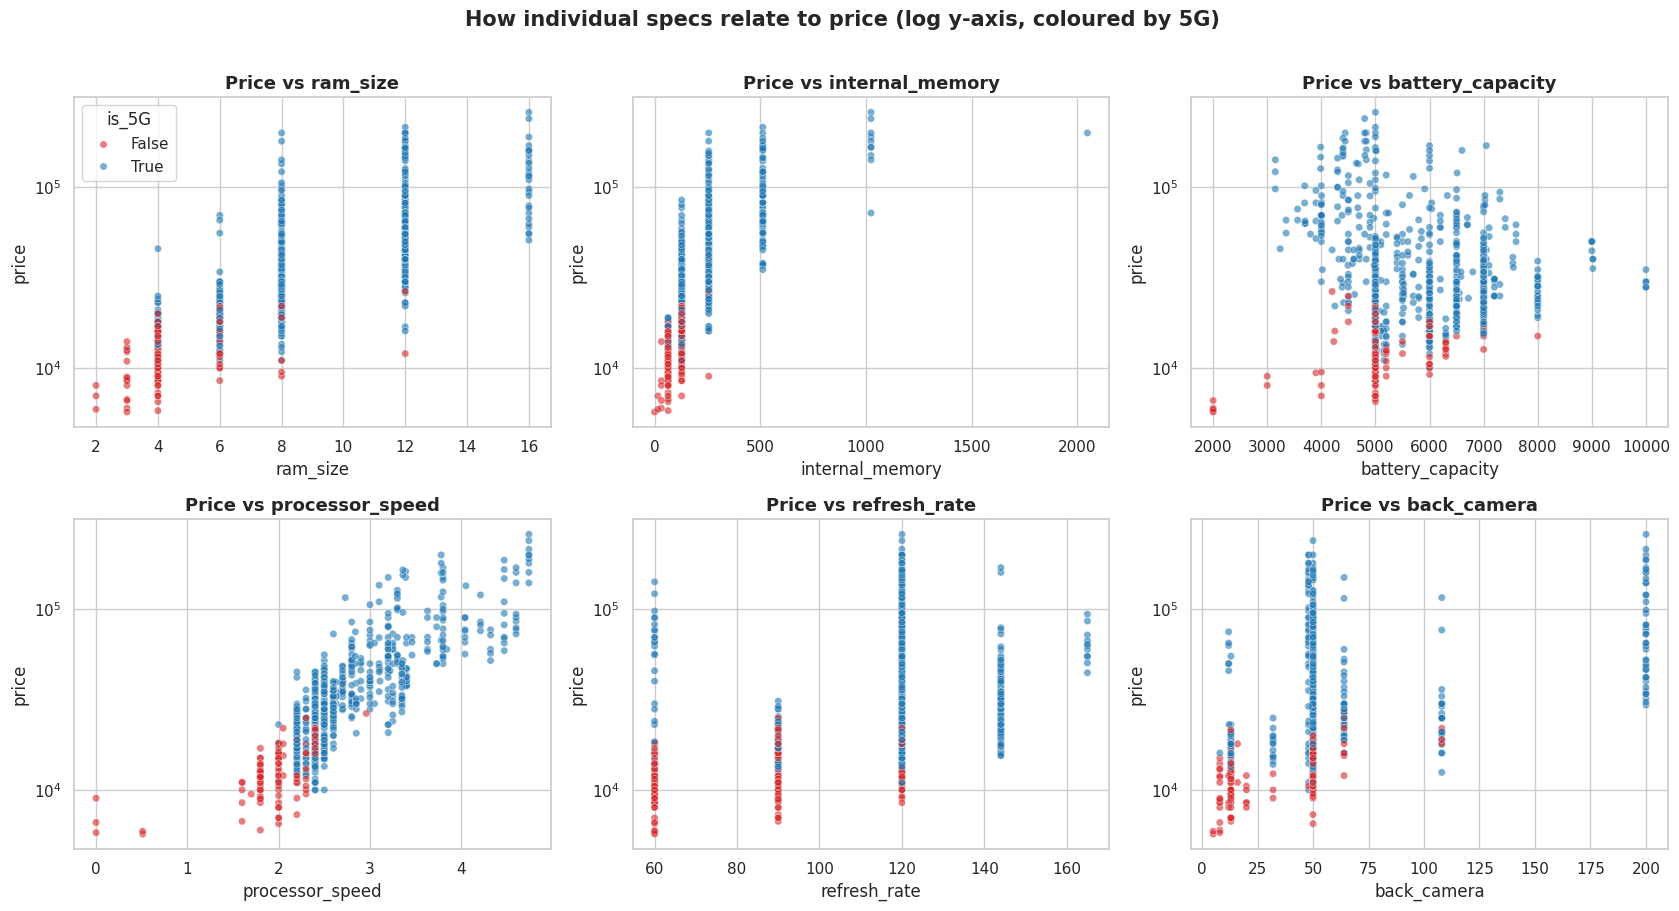

In [8]:
feats = ["ram_size", "internal_memory", "battery_capacity", "processor_speed", "refresh_rate", "back_camera"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, f in zip(axes.ravel(), feats):
    sns.scatterplot(data=df, x=f, y="price", hue="is_5G", alpha=.6, palette={True: "#1f77b4", False: "#d62728"}, ax=ax, s=28)
    ax.set_yscale("log"); ax.set_title(f"Price vs {f}")
    if ax is not axes[0, 0]:
        ax.legend_.remove()
plt.suptitle("How individual specs relate to price (log y-axis, coloured by 5G)", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

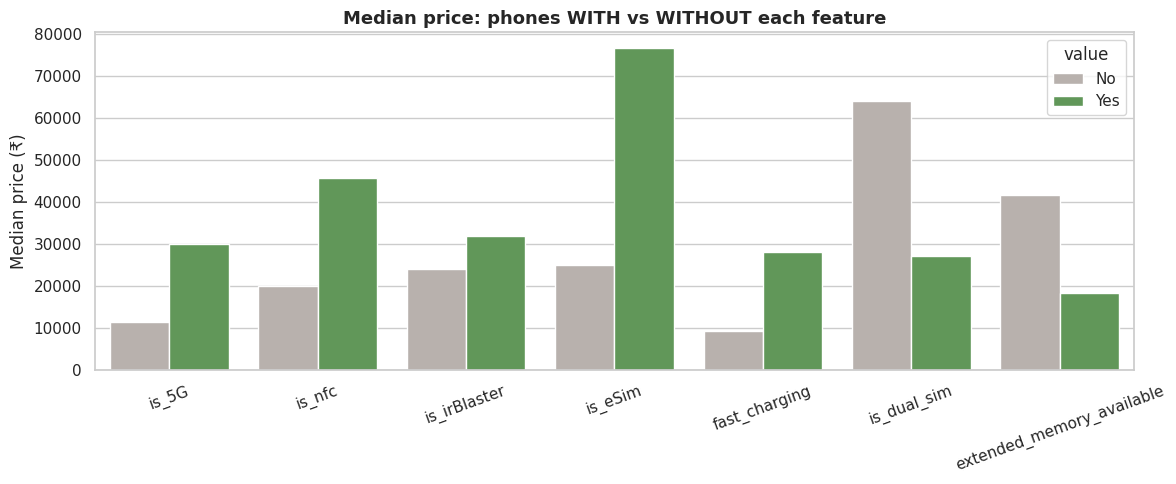

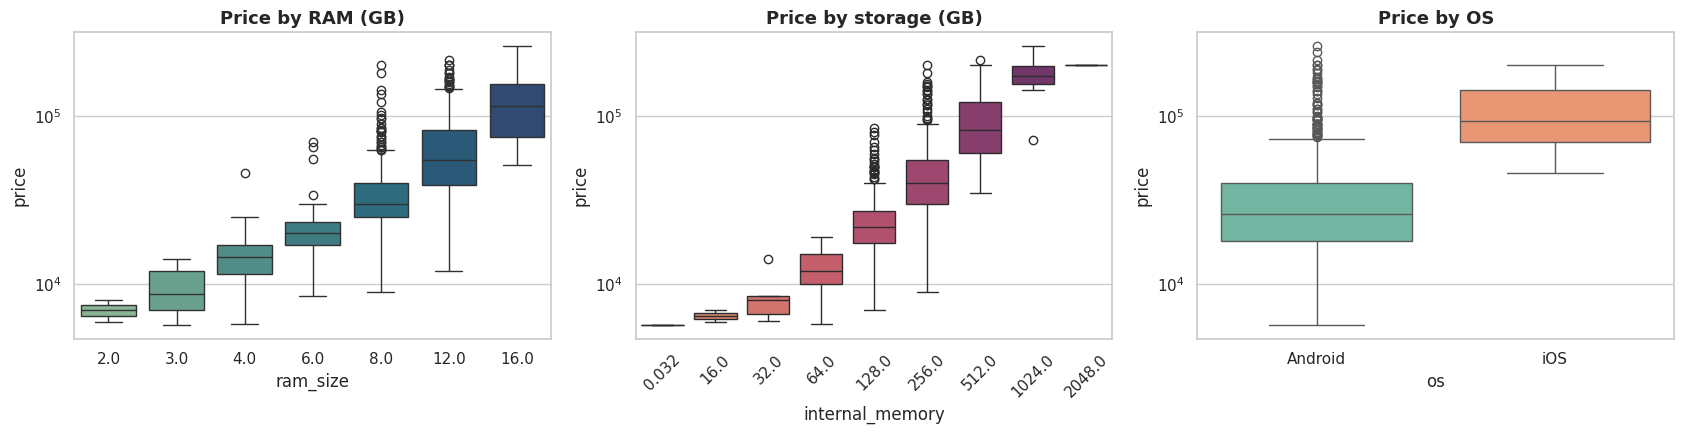

In [9]:
flags = ["is_5G", "is_nfc", "is_irBlaster", "is_eSim", "fast_charging", "is_dual_sim", "extended_memory_available"]
rows = []
for f in flags:
    for val, g in df.groupby(f)["price"]:
        rows.append({"feature": f, "value": "Yes" if val else "No", "median_price": g.median(), "n": len(g)})
flag_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=flag_df, x="feature", y="median_price", hue="value", palette={"Yes": "#59a14f", "No": "#bab0ab"}, ax=ax)
ax.set_title("Median price: phones WITH vs WITHOUT each feature"); ax.set_ylabel("Median price (₹)"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="ram_size", y="price", palette="crest", ax=axes[0]); axes[0].set_yscale("log"); axes[0].set_title("Price by RAM (GB)")
sns.boxplot(data=df, x="internal_memory", y="price", palette="flare", ax=axes[1]); axes[1].set_yscale("log"); axes[1].set_title("Price by storage (GB)")
axes[1].tick_params(axis="x", rotation=45)
sns.boxplot(data=df, x="os", y="price", palette="Set2", ax=axes[2]); axes[2].set_yscale("log"); axes[2].set_title("Price by OS")
plt.tight_layout(); plt.show()

## 3️⃣ Feature engineering & preprocessing

New features derived from raw columns:

* `res_w`, `res_h`, `megapixels`, `ppi` — parsed from the text column `resolution` (+ pixel density using `screen_size`)
* `processor_brand` — high-cardinality `processor_name` (188 values) collapsed to chipset family (Snapdragon, Dimensity, …)
* `total_cameras` — rear + front cameras
* booleans → 0/1, `extend_upto` NaN → 0, `os`/`screen_spec` NaN → "Unknown"

Dropped: `model` (identifier), `processor_name` (replaced), `resolution` (parsed), `rating` (post-launch outcome, 29% missing).

In [10]:
def proc_family(name):
    n = str(name).lower()
    for key, fam in [("snapdragon", "Snapdragon"), ("dimensity", "Dimensity"), ("exynos", "Exynos"),
                     ("helio", "Helio"), ("unisoc", "Unisoc"), ("tiger", "Unisoc"), ("tensor", "Google Tensor"),
                     ("bionic", "Apple"), ("apple", "Apple"), ("kirin", "Kirin"), ("mtk", "MediaTek-other")]:
        if key in n:
            return fam
    return "Other"

BOOL_COLS = ["is_dual_sim", "is_5G", "is_irBlaster", "is_nfc", "is_eSim", "fast_charging", "extended_memory_available"]

def engineer(raw):
    d = raw.copy()
    wh = d["resolution"].astype(str).str.extract(r"(\d+)\s*x\s*(\d+)").astype(float)
    d["res_w"] = wh.min(axis=1)                       # normalise orientation (some rows are WxH, some HxW)
    d["res_h"] = wh.max(axis=1)
    d["megapixels"] = d["res_w"] * d["res_h"] / 1e6
    d["ppi"] = np.sqrt(d["res_w"] ** 2 + d["res_h"] ** 2) / d["screen_size"]
    d["processor_brand"] = d["processor_name"].apply(proc_family)
    d["total_cameras"] = d["no_of_rear"] + d["no_of_front"]
    d["extend_upto"] = d["extend_upto"].fillna(0)
    d["os"] = d["os"].fillna("Unknown")
    d["screen_spec"] = d["screen_spec"].astype(str).str.strip().replace("nan", "Unknown")
    for c in BOOL_COLS:
        d[c] = d[c].astype(int)
    return d

NUM_FEATURES = ["core", "processor_speed", "ram_size", "internal_memory", "battery_capacity", "max_chrg_pwr",
                "screen_size", "refresh_rate", "back_camera", "front_camera", "no_of_rear", "no_of_front",
                "extend_upto", "os_version", "res_w", "res_h", "megapixels", "ppi", "total_cameras"] + BOOL_COLS
CAT_FEATURES = ["brand", "processor_brand", "os", "screen_spec"]
FEATURES = NUM_FEATURES + CAT_FEATURES

data = engineer(df)
print(f"{len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical = {len(FEATURES)} model features")
print("\nProcessor families found:\n", data["processor_brand"].value_counts().to_dict())
display(data[["brand", "model", "resolution", "res_w", "res_h", "megapixels", "ppi", "processor_brand", "total_cameras", "price"]].head())

26 numeric + 4 categorical = 30 model features

Processor families found:
 {'Dimensity': 358, 'Snapdragon': 270, 'Unisoc': 67, 'Exynos': 66, 'Helio': 42, 'Apple': 28, 'Google Tensor': 18, 'Other': 6, 'MediaTek-other': 3}


,brand,model,resolution,res_w,res_h,megapixels,ppi,processor_brand,total_cameras,price
0,vivo,Vivo S2 5G,1260 x 2800,1260.0,2800.0,3.52800,449.551934,Dimensity,3.0,39999
1,oneplus,OnePlus N6x,720 x 1570,720.0,1570.0,1.13040,254.003413,Dimensity,2.0,18999
2,samsung,Samsung Galaxy F70 Pro 5G,1080 x 2340,1080.0,2340.0,2.52720,384.657879,Snapdragon,4.0,23999
3,poco,Poco M8 Power,2396 x 1080,1080.0,2396.0,2.58768,375.988311,Snapdragon,3.0,24999
4,vivo,Vivo T4 Pro 5G (8GB RAM + 256GB),1080 x 2392,1080.0,2392.0,2.58336,387.667968,Snapdragon,4.0,29999


In [11]:
X = data[FEATURES]
y = data["price"]

# stratify the split on price quintiles so train & test have the same price mix
strata = pd.qcut(y, 5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=strata)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Median price  train ₹{y_train.median():,.0f}  |  test ₹{y_test.median():,.0f}")

# Preprocessing lives INSIDE the pipeline → imputer / encoder are fitted on training folds only (no leakage)
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False))]),
     CAT_FEATURES),
])

def make_model(estimator):
    # log-transform the target, fit, then convert predictions back to rupees
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def reg_metrics(y_true, y_pred):
    return {"MAE (₹)": mean_absolute_error(y_true, y_pred),
            "RMSE (₹)": root_mean_squared_error(y_true, y_pred),
            "MedAE (₹)": median_absolute_error(y_true, y_pred),
            "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
            "R²": r2_score(y_true, y_pred),
            "R² (log)": r2_score(np.log1p(y_true), np.log1p(y_pred))}
print("Pipeline helpers ready ✔")

Train: (686, 30)   Test: (172, 30)
Median price  train ₹27,771  |  test ₹26,999
Pipeline helpers ready ✔


## 4️⃣ Modelling

### 4.1 Baseline models (sensible defaults) with 5-fold cross-validation on the training set

In [12]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = {
    "Random Forest":     make_model(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_model(GradientBoostingRegressor(n_estimators=300, random_state=RANDOM_STATE)),
}
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, mdl in baseline.items():
    cvres = cross_validate(mdl, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=-1, return_train_score=False)
    rows.append({"Model": name, "CV R²": cvres["test_r2"].mean(), "CV R² std": cvres["test_r2"].std(),
                 "CV MAE (₹)": -cvres["test_mae"].mean(), "CV RMSE (₹)": -cvres["test_rmse"].mean(),
                 "Fit time / fold (s)": cvres["fit_time"].mean()})
baseline_cv = pd.DataFrame(rows).set_index("Model")
print("Baseline 5-fold CV (training data only):")
display(baseline_cv.round(3))

Baseline 5-fold CV (training data only):


,CV R²,CV R² std,CV MAE (₹),CV RMSE (₹),Fit time / fold (s)
Model,,,,,
Random Forest,0.897,0.039,5585.159,10772.780,1.092
Gradient Boosting,0.919,0.036,5063.589,9423.637,0.447


### 4.2 Hyper-parameter tuning — `RandomizedSearchCV` (25 candidates × 5 folds each, optimising MAE)

In [13]:
rf_space = {
    "regressor__model__n_estimators": [200, 300, 500, 700],
    "regressor__model__max_depth": [None, 8, 12, 16, 24],
    "regressor__model__min_samples_split": [2, 4, 8, 12],
    "regressor__model__min_samples_leaf": [1, 2, 3, 5],
    "regressor__model__max_features": ["sqrt", 0.3, 0.5, 0.7, 1.0],
}
rf_search = RandomizedSearchCV(make_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
                               rf_space, n_iter=25, cv=cv5, scoring="neg_mean_absolute_error",
                               random_state=RANDOM_STATE, n_jobs=1, refit=True)
t0 = time.time(); rf_search.fit(X_train, y_train); rf_time = time.time() - t0
print(f"🌲 Random Forest tuned in {rf_time:.0f}s")
print(f"   best CV MAE = ₹{-rf_search.best_score_:,.0f}")
for k, v in rf_search.best_params_.items(): print(f"   {k.split('__')[-1]:<18} {v}")

🌲 Random Forest tuned in 91s
   best CV MAE = ₹5,515
   n_estimators       300
   min_samples_split  2
   min_samples_leaf   1
   max_features       0.3
   max_depth          None


In [14]:
gb_space = {
    "regressor__model__n_estimators": [200, 300, 500, 800],
    "regressor__model__learning_rate": [0.02, 0.05, 0.08, 0.12],
    "regressor__model__max_depth": [2, 3, 4, 5],
    "regressor__model__subsample": [0.6, 0.8, 1.0],
    "regressor__model__min_samples_leaf": [1, 3, 5, 10],
    "regressor__model__max_features": [None, "sqrt", 0.7],
}
gb_search = RandomizedSearchCV(make_model(GradientBoostingRegressor(random_state=RANDOM_STATE)),
                               gb_space, n_iter=25, cv=cv5, scoring="neg_mean_absolute_error",
                               random_state=RANDOM_STATE, n_jobs=-1, refit=True)
t0 = time.time(); gb_search.fit(X_train, y_train); gb_time = time.time() - t0
print(f"🚀 Gradient Boosting tuned in {gb_time:.0f}s")
print(f"   best CV MAE = ₹{-gb_search.best_score_:,.0f}")
for k, v in gb_search.best_params_.items(): print(f"   {k.split('__')[-1]:<18} {v}")

rf_best, gb_best = rf_search.best_estimator_, gb_search.best_estimator_

🚀 Gradient Boosting tuned in 64s
   best CV MAE = ₹4,410
   subsample          1.0
   n_estimators       500
   min_samples_leaf   1
   max_features       sqrt
   max_depth          5
   learning_rate      0.08


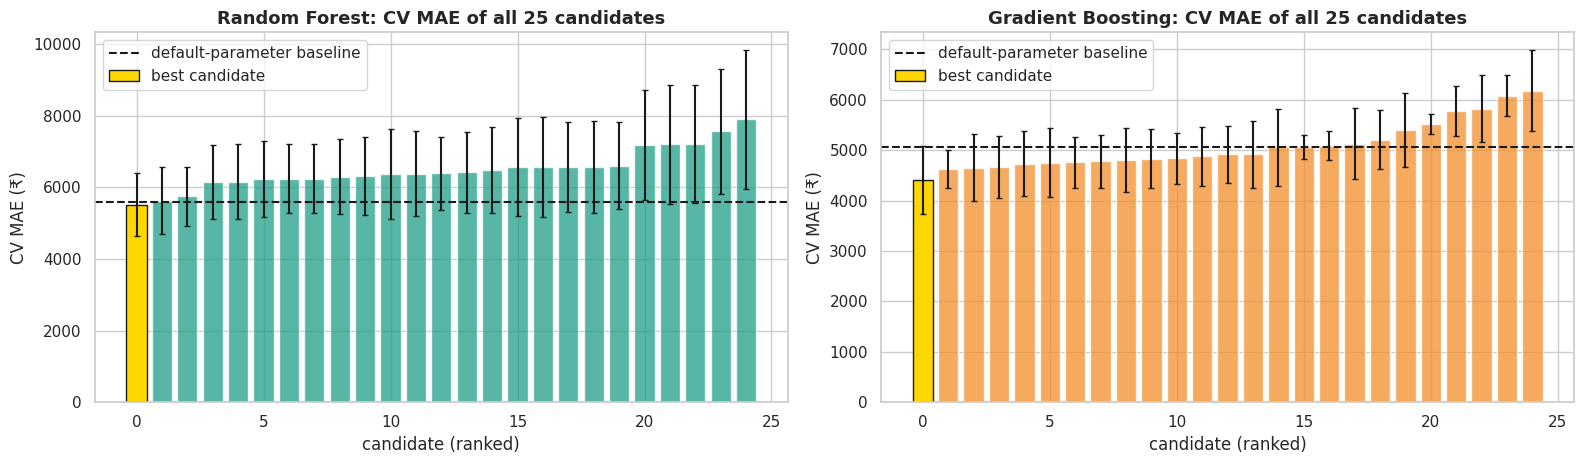

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=False)
for ax, search, col, title in [(axes[0], rf_search, RF_C, "Random Forest"), (axes[1], gb_search, GB_C, "Gradient Boosting")]:
    r = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    mae = -r["mean_test_score"].values
    sd = r["std_test_score"].values
    ax.bar(range(len(r)), mae, yerr=sd, color=col, alpha=.75, capsize=2)
    ax.bar(0, mae[0], color="gold", edgecolor="k", label="best candidate")
    ax.axhline(baseline_cv.loc[title, "CV MAE (₹)"], color="k", ls="--", label="default-parameter baseline")
    ax.set_title(f"{title}: CV MAE of all 25 candidates"); ax.set_xlabel("candidate (ranked)"); ax.set_ylabel("CV MAE (₹)")
    ax.legend()
plt.tight_layout(); plt.show()

### 4.3 Final evaluation on the held-out **test set** (never seen during tuning)

In [16]:
baseline_fit = {}
for name, mdl in baseline.items():
    t0 = time.time(); baseline_fit[name] = mdl.fit(X_train, y_train); baseline_fit[name].fit_s = time.time() - t0

models = {"RF (baseline)": baseline_fit["Random Forest"], "GB (baseline)": baseline_fit["Gradient Boosting"],
          "RF (tuned)": rf_best, "GB (tuned)": gb_best}

preds_test, preds_train, metric_rows = {}, {}, []
for name, m in models.items():
    preds_test[name], preds_train[name] = m.predict(X_test), m.predict(X_train)
    r = reg_metrics(y_test, preds_test[name])
    r["Train R²"] = r2_score(y_train, preds_train[name])
    metric_rows.append({"Model": name, **r})
results = pd.DataFrame(metric_rows).set_index("Model")
display(results.round(3))

best_name = results["MAE (₹)"].idxmin()
print(f"\n🏆 Lowest test MAE: {best_name}  (₹{results.loc[best_name, 'MAE (₹)']:,.0f} average error)")

,MAE (₹),RMSE (₹),MedAE (₹),MAPE (%),R²,R² (log),Train R²
Model,,,,,,,
RF (baseline),5790.299,11414.295,2500.325,13.984,0.882,0.932,0.988
GB (baseline),4430.489,8881.725,1857.126,11.252,0.929,0.951,0.989
RF (tuned),5536.515,11554.883,2371.396,13.539,0.879,0.936,0.987
GB (tuned),3886.843,8088.431,1918.489,10.751,0.941,0.956,0.999



🏆 Lowest test MAE: GB (tuned)  (₹3,887 average error)


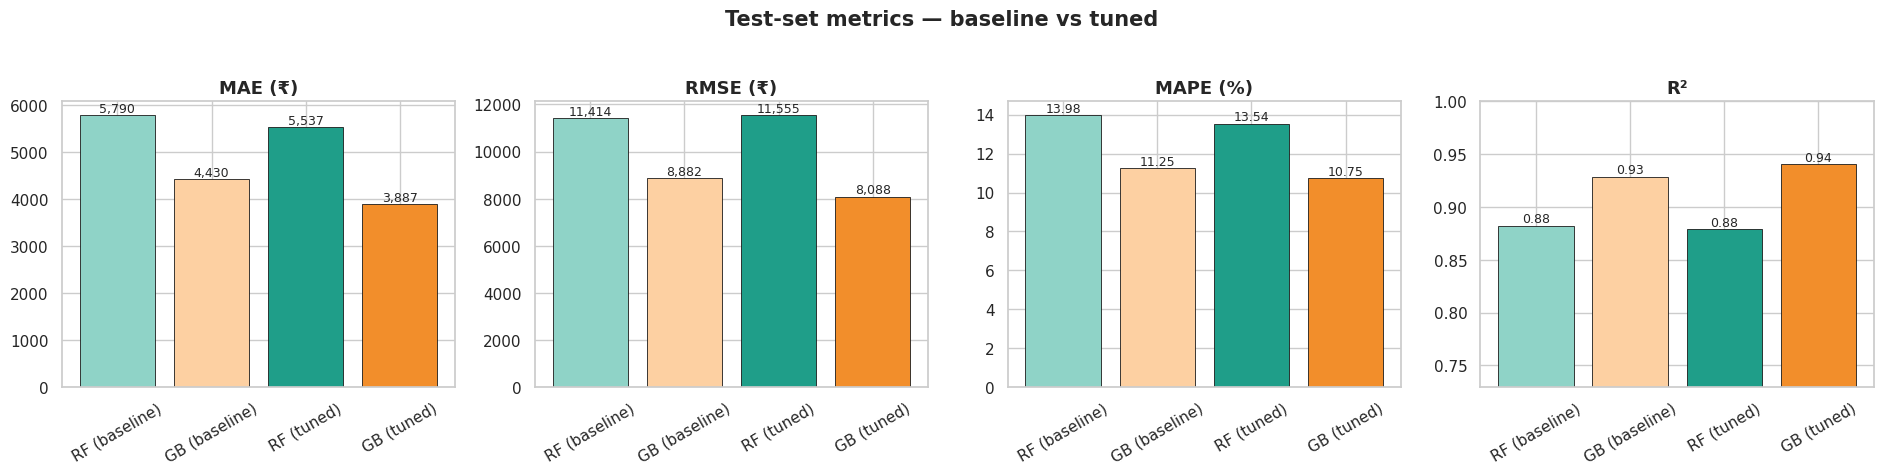

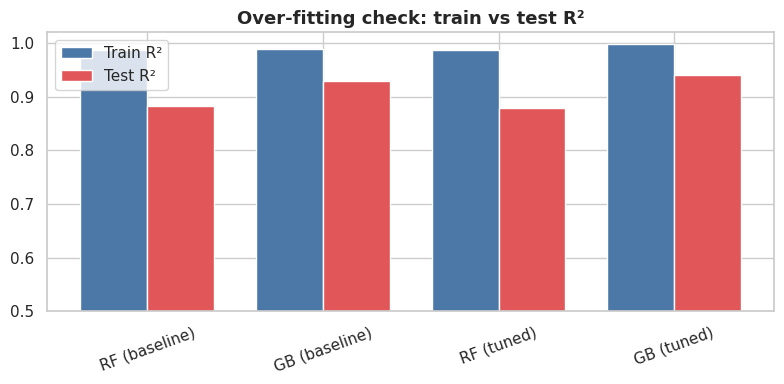

In [17]:
metric_plot = ["MAE (₹)", "RMSE (₹)", "MAPE (%)", "R²"]
colors = {"RF (baseline)": "#8fd3c7", "GB (baseline)": "#fdd0a2", "RF (tuned)": RF_C, "GB (tuned)": GB_C}

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, met in zip(axes, metric_plot):
    vals = results[met]
    bars = ax.bar(vals.index, vals.values, color=[colors[i] for i in vals.index], edgecolor="k", lw=.6)
    ax.set_title(met); ax.tick_params(axis="x", rotation=30)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.2f}" if met in ("R²", "MAPE (%)") else f"{v:,.0f}",
                ha="center", va="bottom", fontsize=9)
    if met == "R²": ax.set_ylim(max(0, vals.min() - .15), 1.0)
plt.suptitle("Test-set metrics — baseline vs tuned", y=1.03, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

# overfitting check: train vs test R²
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(results)); w = .38
ax.bar(x - w/2, results["Train R²"], w, label="Train R²", color="#4c78a8")
ax.bar(x + w/2, results["R²"], w, label="Test R²", color="#e15759")
ax.set_xticks(x); ax.set_xticklabels(results.index, rotation=20); ax.set_ylim(.5, 1.02); ax.legend()
ax.set_title("Over-fitting check: train vs test R²")
plt.tight_layout(); plt.show()

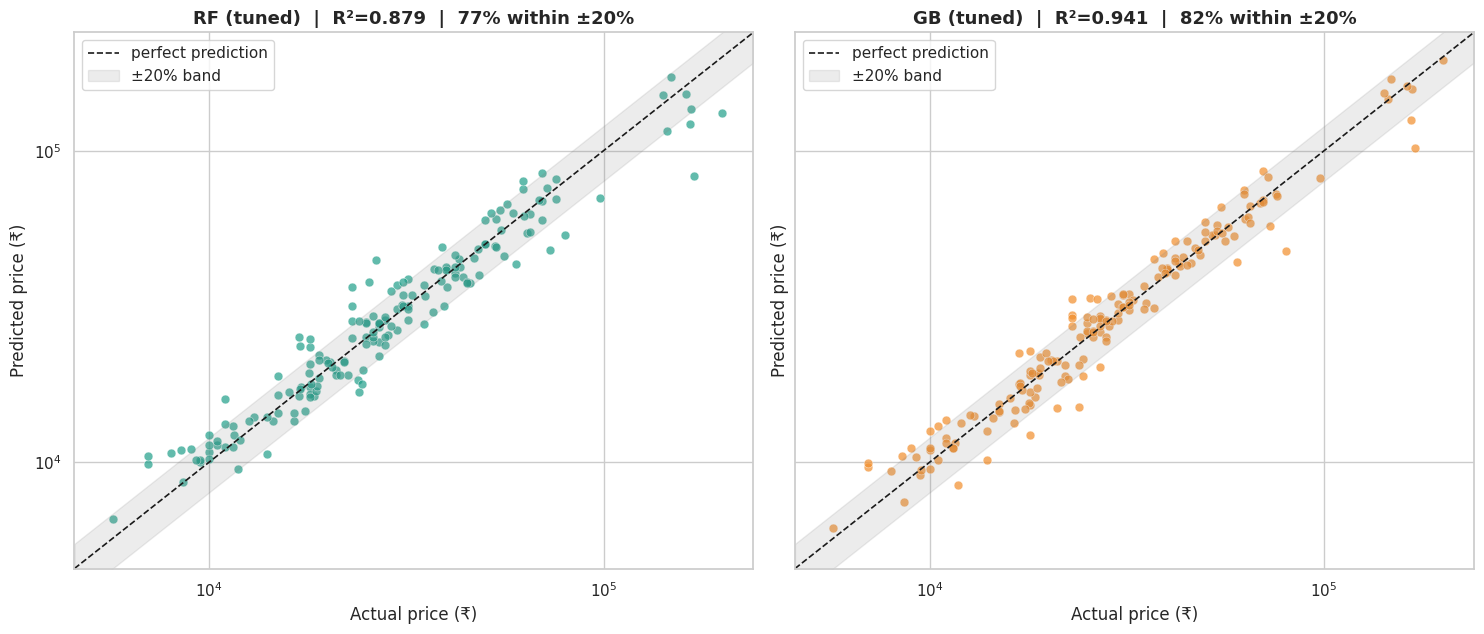

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
lim = [y_test.min() * .8, y_test.max() * 1.2]
for ax, name, col in [(axes[0], "RF (tuned)", RF_C), (axes[1], "GB (tuned)", GB_C)]:
    ax.scatter(y_test, preds_test[name], s=40, alpha=.7, color=col, edgecolor="white", lw=.4)
    ax.plot(lim, lim, "k--", lw=1.2, label="perfect prediction")
    ax.fill_between(lim, [l * .8 for l in lim], [l * 1.2 for l in lim], color="grey", alpha=.15, label="±20% band")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    within = (np.abs(preds_test[name] - y_test) / y_test <= .2).mean() * 100
    ax.set_title(f"{name}  |  R²={results.loc[name,'R²']:.3f}  |  {within:.0f}% within ±20%")
    ax.set_xlabel("Actual price (₹)"); ax.set_ylabel("Predicted price (₹)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

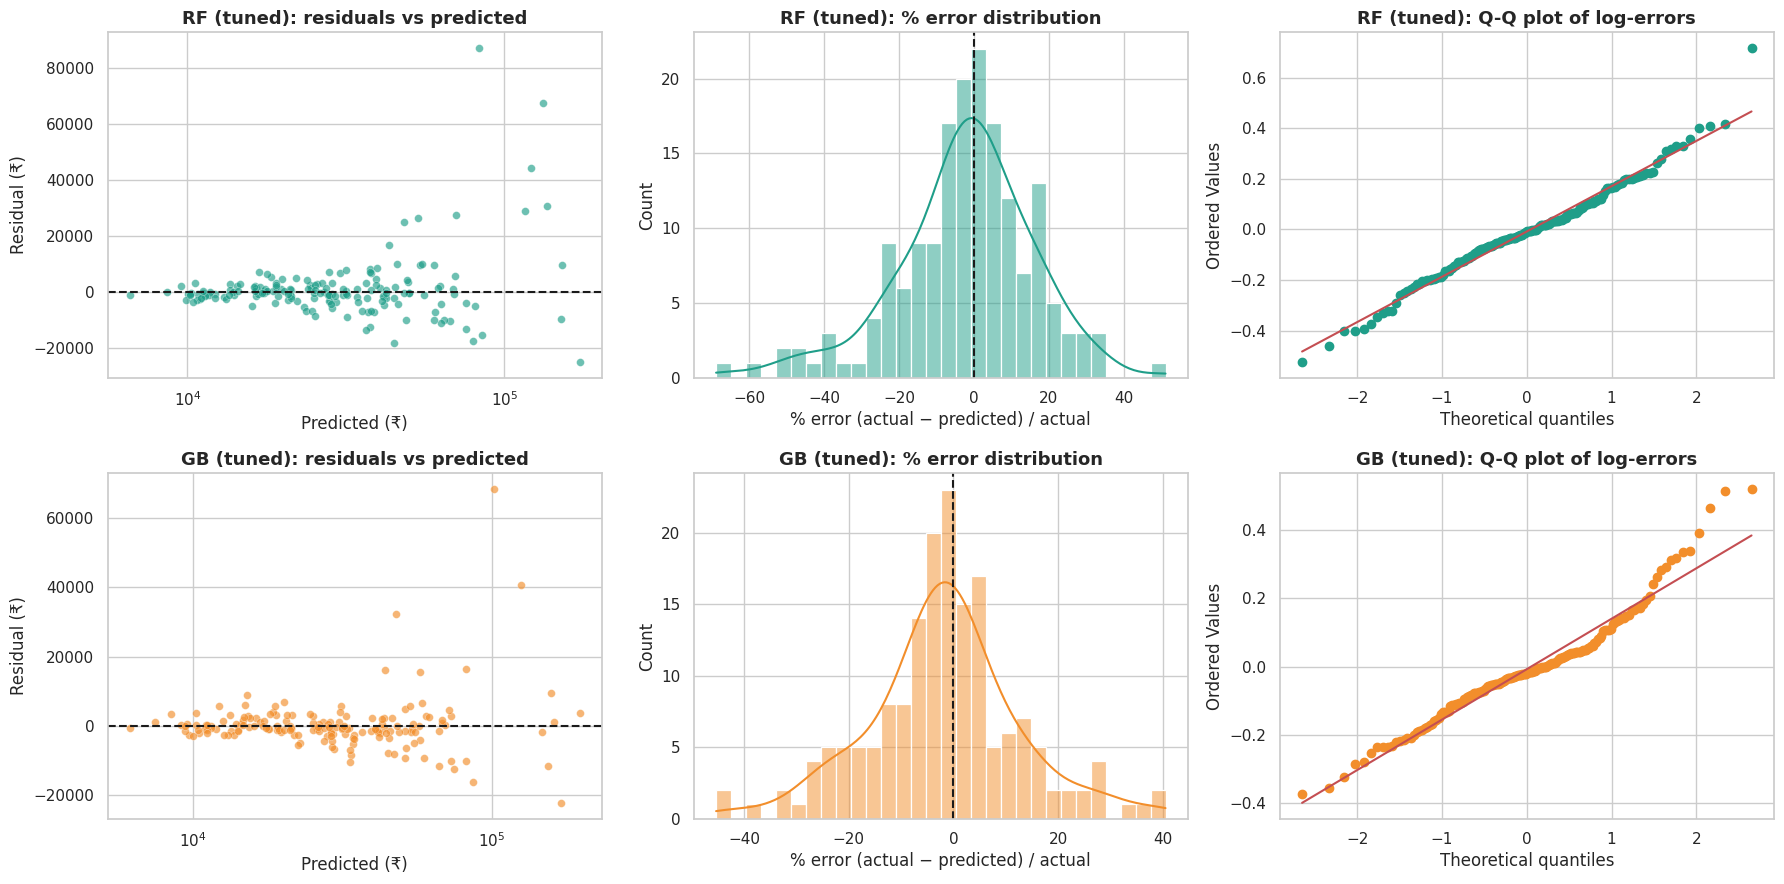

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, (name, col) in enumerate([("RF (tuned)", RF_C), ("GB (tuned)", GB_C)]):
    res = y_test.values - preds_test[name]
    pct = res / y_test.values * 100
    axes[r, 0].scatter(preds_test[name], res, color=col, alpha=.65, s=32, edgecolor="white", lw=.3)
    axes[r, 0].axhline(0, color="k", ls="--"); axes[r, 0].set_xscale("log")
    axes[r, 0].set_title(f"{name}: residuals vs predicted"); axes[r, 0].set_xlabel("Predicted (₹)"); axes[r, 0].set_ylabel("Residual (₹)")
    sns.histplot(pct, bins=30, kde=True, color=col, ax=axes[r, 1])
    axes[r, 1].axvline(0, color="k", ls="--"); axes[r, 1].set_title(f"{name}: % error distribution")
    axes[r, 1].set_xlabel("% error (actual − predicted) / actual")
    stats.probplot(np.log(y_test.values) - np.log(preds_test[name]), dist="norm", plot=axes[r, 2])
    axes[r, 2].get_lines()[0].set_color(col); axes[r, 2].set_title(f"{name}: Q-Q plot of log-errors")
plt.tight_layout(); plt.show()

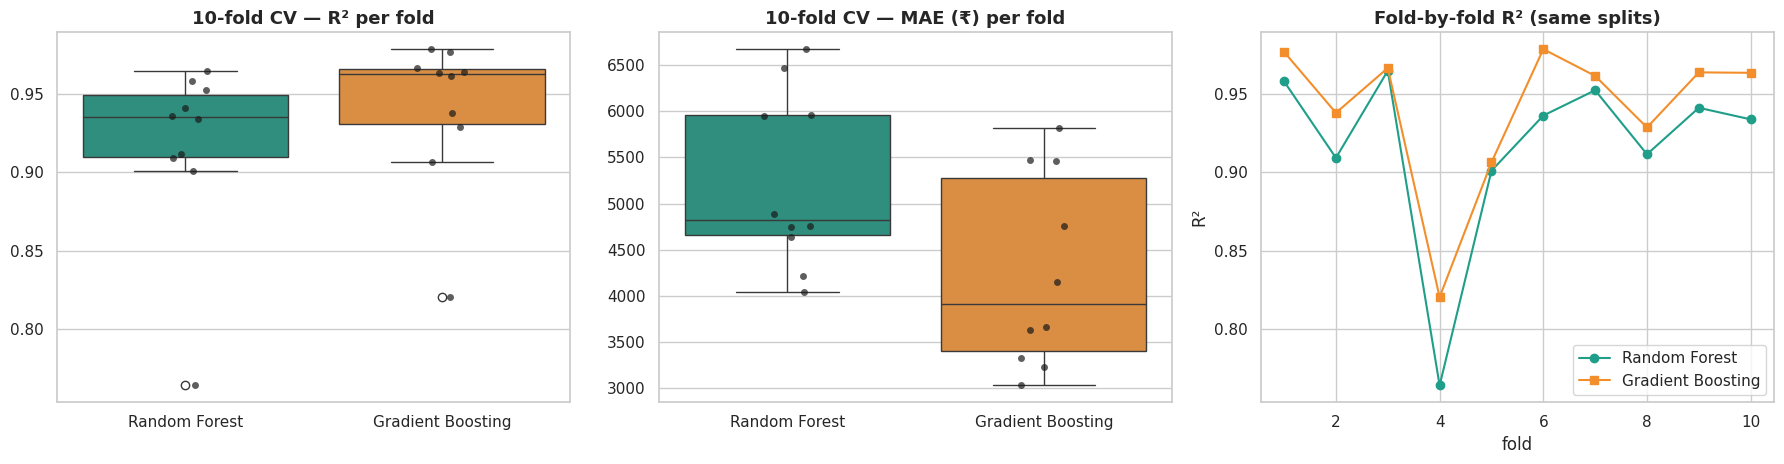

Mean CV R²   RF=0.917±0.055   GB=0.940±0.045
Mean CV MAE  RF=₹5,233   GB=₹4,256
Paired t-test on fold MAE: t=11.30, p=0.0000  →  difference is statistically significant (informal, folds overlap)


In [20]:
# 10-fold CV on the training set with the TUNED models → stability of each model
cv10 = KFold(n_splits=10, shuffle=True, random_state=7)
cv_scores = {n: cross_val_score(m, X_train, y_train, cv=cv10, scoring="r2", n_jobs=-1)
             for n, m in [("Random Forest", rf_best), ("Gradient Boosting", gb_best)]}
cv_mae = {n: -cross_val_score(m, X_train, y_train, cv=cv10, scoring="neg_mean_absolute_error", n_jobs=-1)
          for n, m in [("Random Forest", rf_best), ("Gradient Boosting", gb_best)]}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.boxplot(data=pd.DataFrame(cv_scores), palette=[RF_C, GB_C], ax=axes[0])
sns.stripplot(data=pd.DataFrame(cv_scores), color="k", size=5, alpha=.7, ax=axes[0])
axes[0].set_title("10-fold CV — R² per fold")
sns.boxplot(data=pd.DataFrame(cv_mae), palette=[RF_C, GB_C], ax=axes[1])
sns.stripplot(data=pd.DataFrame(cv_mae), color="k", size=5, alpha=.7, ax=axes[1])
axes[1].set_title("10-fold CV — MAE (₹) per fold")
axes[2].plot(range(1, 11), cv_scores["Random Forest"], "o-", color=RF_C, label="Random Forest")
axes[2].plot(range(1, 11), cv_scores["Gradient Boosting"], "s-", color=GB_C, label="Gradient Boosting")
axes[2].set_xlabel("fold"); axes[2].set_ylabel("R²"); axes[2].legend(); axes[2].set_title("Fold-by-fold R² (same splits)")
plt.tight_layout(); plt.show()

t, p = stats.ttest_rel(cv_mae["Random Forest"], cv_mae["Gradient Boosting"])
print(f"Mean CV R²   RF={cv_scores['Random Forest'].mean():.3f}±{cv_scores['Random Forest'].std():.3f}   "
      f"GB={cv_scores['Gradient Boosting'].mean():.3f}±{cv_scores['Gradient Boosting'].std():.3f}")
print(f"Mean CV MAE  RF=₹{cv_mae['Random Forest'].mean():,.0f}   GB=₹{cv_mae['Gradient Boosting'].mean():,.0f}")
print(f"Paired t-test on fold MAE: t={t:.2f}, p={p:.4f}  →  " + ("difference is statistically significant (informal, folds overlap)" if p < .05 else "no significant difference between the models"))

## 5️⃣ Model interpretation — *what drives the price?*

### 5.1 Built-in (impurity-based) feature importance

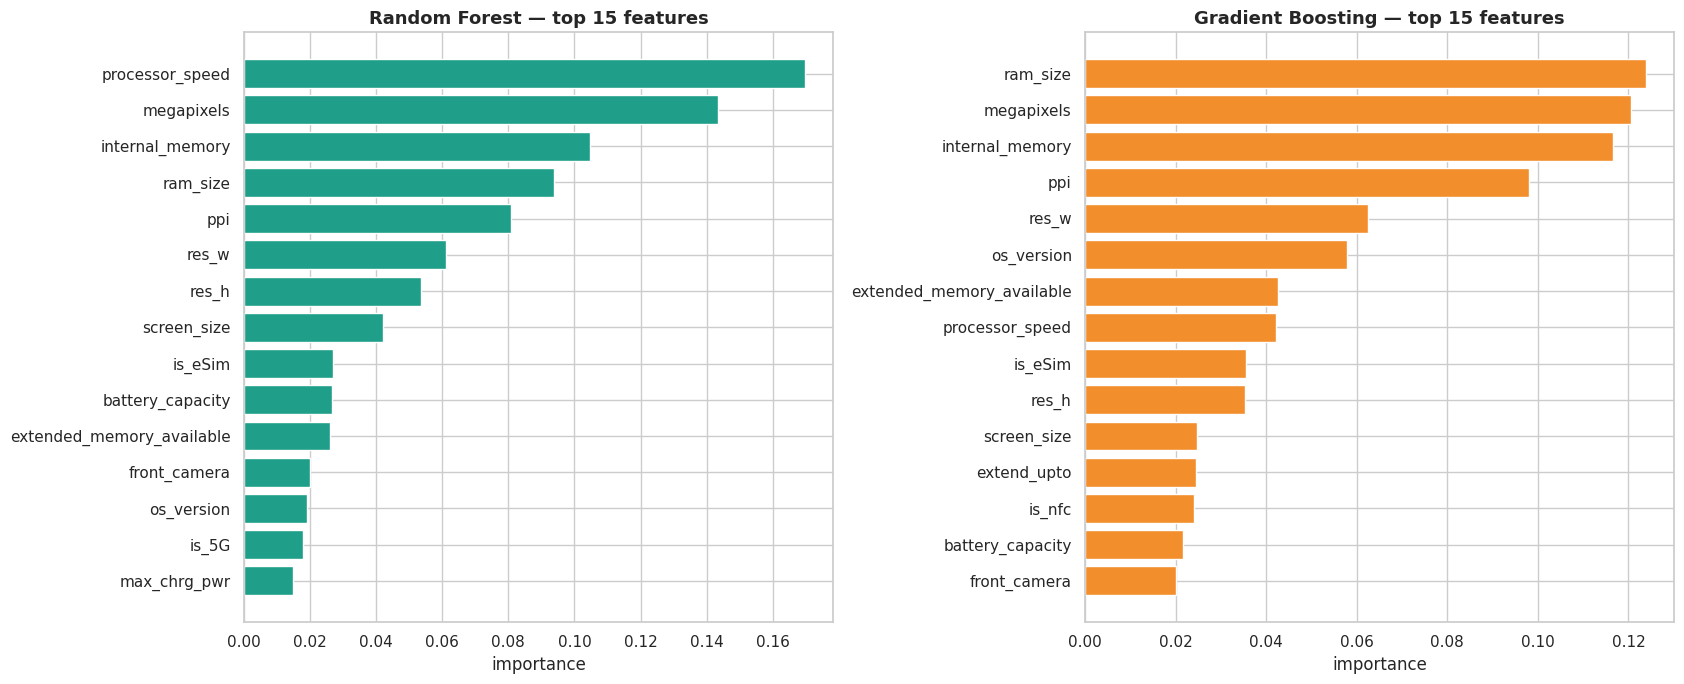

Top-5 per model:


,RF,GB
0,processor_speed,ram_size
1,megapixels,megapixels
2,internal_memory,internal_memory
3,ram_size,ppi
4,ppi,res_w


In [21]:
def impurity_importance(m):
    prep = m.regressor_.named_steps["prep"]
    names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    imp = m.regressor_.named_steps["model"].feature_importances_
    return pd.Series(imp, index=names).sort_values(ascending=False)

imp_rf, imp_gb = impurity_importance(rf_best), impurity_importance(gb_best)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, imp, col, title in [(axes[0], imp_rf, RF_C, "Random Forest"), (axes[1], imp_gb, GB_C, "Gradient Boosting")]:
    top = imp.head(15)[::-1]
    ax.barh(top.index, top.values, color=col)
    ax.set_title(f"{title} — top 15 features"); ax.set_xlabel("importance")
plt.tight_layout(); plt.show()

both = pd.concat([imp_rf.rename("RF"), imp_gb.rename("GB")], axis=1).fillna(0)
print("Top-5 per model:")
display(pd.DataFrame({"RF": imp_rf.head(5).index, "GB": imp_gb.head(5).index}))

### 5.2 Permutation importance (on the unseen test set, in ₹ of MAE damage)

More reliable than impurity importance: shuffle one raw column and measure how much the error increases.

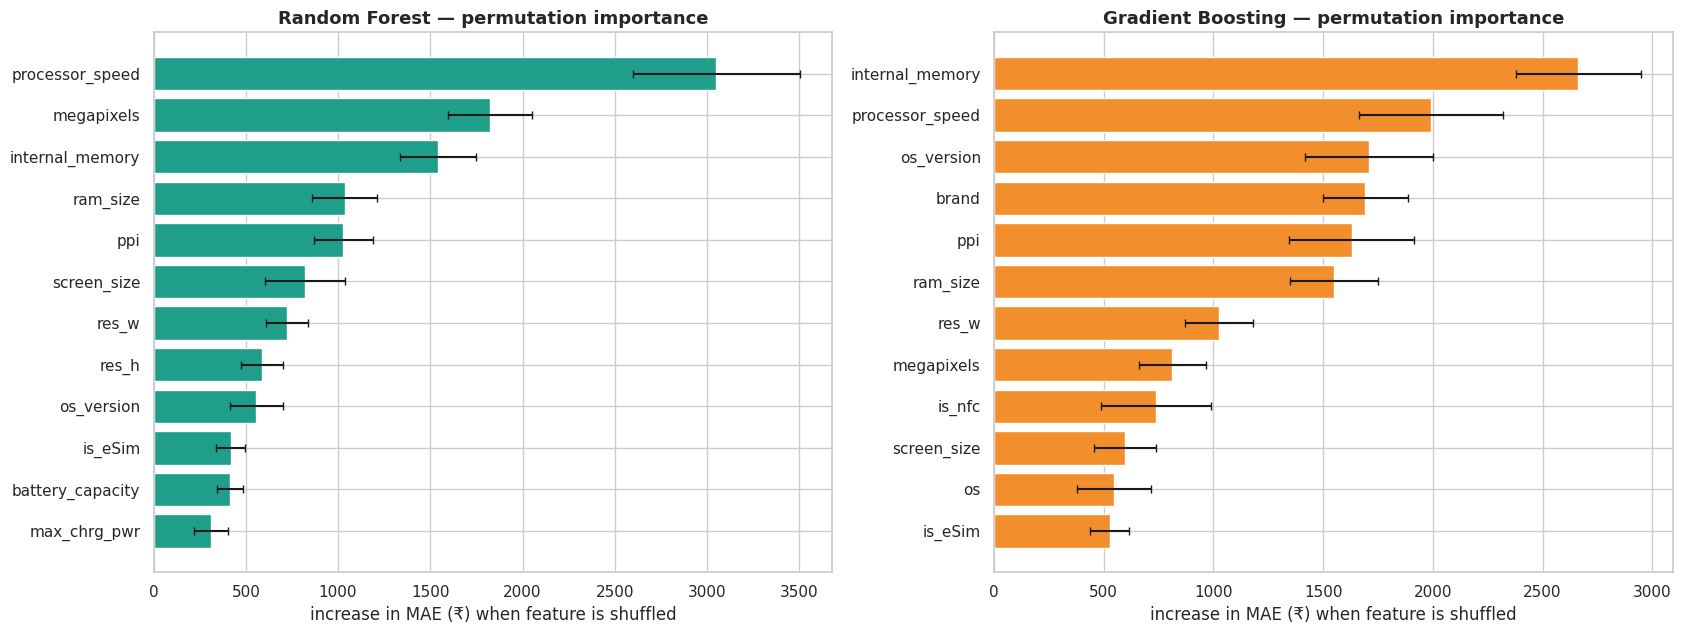

In [22]:
perm = {}
for name, m in [("Random Forest", rf_best), ("Gradient Boosting", gb_best)]:
    pi = permutation_importance(m, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE,
                                scoring="neg_mean_absolute_error", n_jobs=-1)
    perm[name] = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, (name, col) in zip(axes, [("Random Forest", RF_C), ("Gradient Boosting", GB_C)]):
    top = perm[name].head(12)[::-1]
    ax.barh(top.index, top["mean"], xerr=top["std"], color=col, capsize=3)
    ax.set_title(f"{name} — permutation importance"); ax.set_xlabel("increase in MAE (₹) when feature is shuffled")
plt.tight_layout(); plt.show()

### 5.3 Partial dependence — the *shape* of each feature's effect on price (both models overlaid)

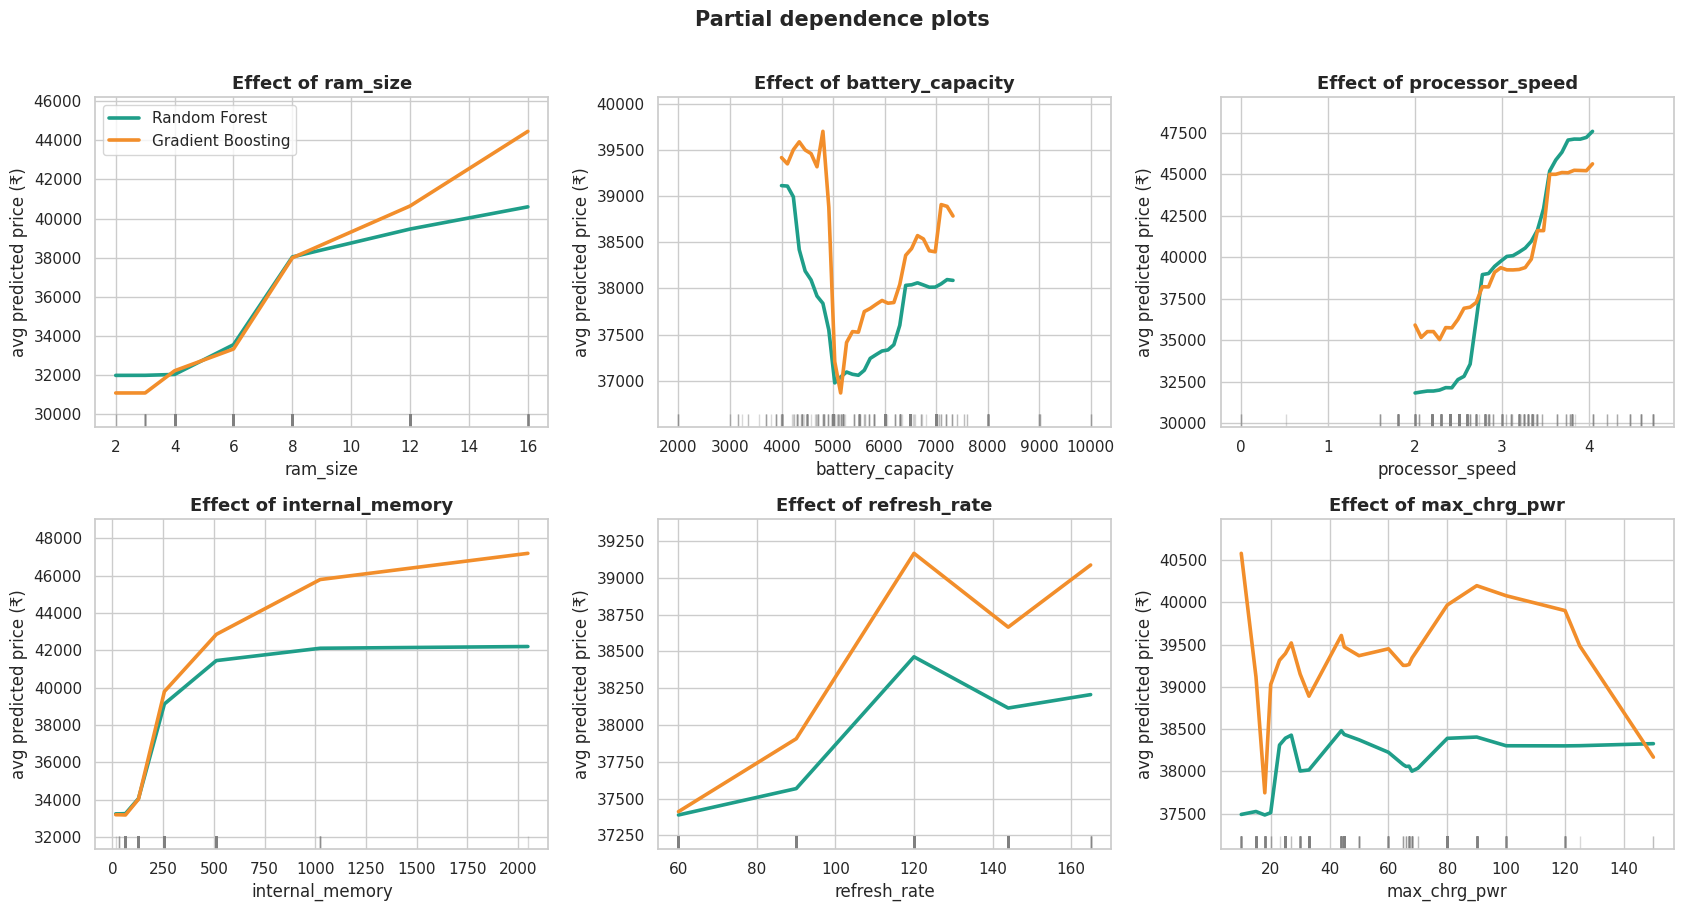

In [23]:
pdp_feats = ["ram_size", "battery_capacity", "processor_speed", "internal_memory", "refresh_rate", "max_chrg_pwr"]
X_pdp = X_train.copy()
X_pdp[NUM_FEATURES] = X_pdp[NUM_FEATURES].fillna(X_pdp[NUM_FEATURES].median())

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, f in zip(axes.ravel(), pdp_feats):
    for name, m, col in [("Random Forest", rf_best, RF_C), ("Gradient Boosting", gb_best, GB_C)]:
        pd_res = partial_dependence(m, X_pdp, [f], grid_resolution=30, kind="average")
        ax.plot(pd_res["grid_values"][0], pd_res["average"][0], lw=2.6, color=col, label=name)
    ax.set_title(f"Effect of {f}"); ax.set_xlabel(f); ax.set_ylabel("avg predicted price (₹)")
    sns.rugplot(X_pdp[f], ax=ax, color="grey", alpha=.3, height=.04)
axes[0, 0].legend()
plt.suptitle("Partial dependence plots", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

### 5.4 Learning curves — would more data help? Bias vs variance

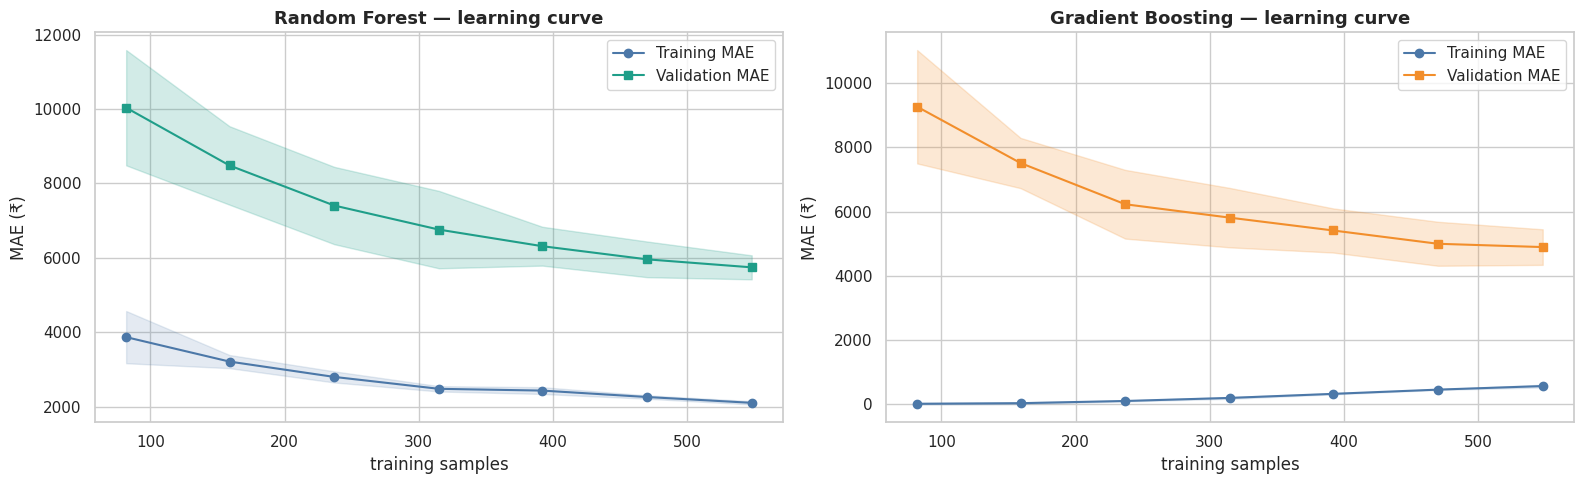

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, m, col) in zip(axes, [("Random Forest", rf_best, RF_C), ("Gradient Boosting", gb_best, GB_C)]):
    sizes, tr, va = learning_curve(m, X_train, y_train, cv=5, scoring="neg_mean_absolute_error",
                                   train_sizes=np.linspace(.15, 1.0, 7), n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
    tr, va = -tr, -va
    ax.plot(sizes, tr.mean(1), "o-", color="#4c78a8", label="Training MAE")
    ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color="#4c78a8", alpha=.15)
    ax.plot(sizes, va.mean(1), "s-", color=col, label="Validation MAE")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=col, alpha=.2)
    ax.set_title(f"{name} — learning curve"); ax.set_xlabel("training samples"); ax.set_ylabel("MAE (₹)"); ax.legend()
plt.tight_layout(); plt.show()

## 6️⃣ Error analysis

To get enough samples per group, out-of-fold predictions are generated for **all 858 phones** (each phone is predicted by a model that never saw it).

,n,MAE_RF,MAE_GB,MAPE_RF,MAPE_GB
segment,,,,,
Budget\n<15k,138,1724.5,1545.5,16.2,14.7
Mid\n15–30k,363,2659.6,2227.6,12.1,10.1
Upper-mid\n30–60k,227,4404.7,3727.9,10.4,8.5
Flagship\n>60k,130,17427.9,12963.9,15.5,12.2


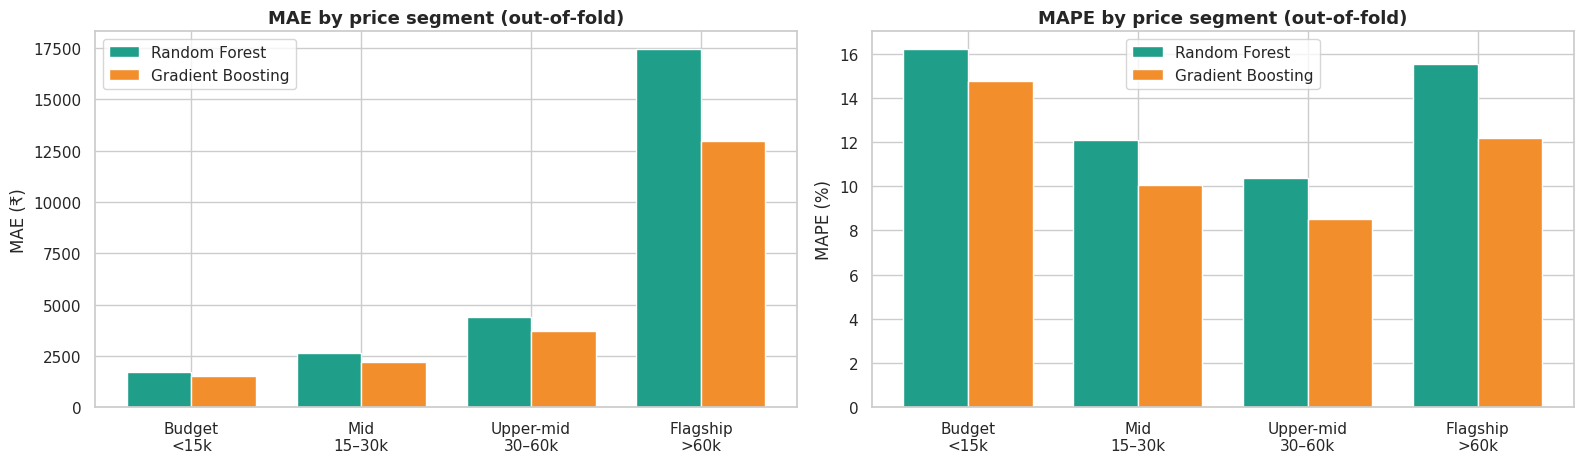

In [25]:
cv_oof = KFold(n_splits=5, shuffle=True, random_state=123)
oof = data[["brand", "model", "price"]].copy()
oof["pred_RF"] = cross_val_predict(rf_best, X, y, cv=cv_oof, n_jobs=-1)
oof["pred_GB"] = cross_val_predict(gb_best, X, y, cv=cv_oof, n_jobs=-1)
for m in ["RF", "GB"]:
    oof[f"ape_{m}"] = (oof[f"pred_{m}"] - oof["price"]).abs() / oof["price"] * 100
    oof[f"ae_{m}"] = (oof[f"pred_{m}"] - oof["price"]).abs()

oof["segment"] = pd.cut(oof["price"], [0, 15000, 30000, 60000, np.inf], labels=["Budget\n<15k", "Mid\n15–30k", "Upper-mid\n30–60k", "Flagship\n>60k"])
seg = oof.groupby("segment", observed=True).agg(n=("price", "size"), MAE_RF=("ae_RF", "mean"), MAE_GB=("ae_GB", "mean"),
                                                MAPE_RF=("ape_RF", "mean"), MAPE_GB=("ape_GB", "mean"))
display(seg.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
x = np.arange(len(seg)); w = .38
for ax, kind, ylab in [(axes[0], "MAE", "MAE (₹)"), (axes[1], "MAPE", "MAPE (%)")]:
    ax.bar(x - w/2, seg[f"{kind}_RF"], w, color=RF_C, label="Random Forest")
    ax.bar(x + w/2, seg[f"{kind}_GB"], w, color=GB_C, label="Gradient Boosting")
    ax.set_xticks(x); ax.set_xticklabels(seg.index); ax.set_ylabel(ylab); ax.legend()
    ax.set_title(f"{kind} by price segment (out-of-fold)")
plt.tight_layout(); plt.show()

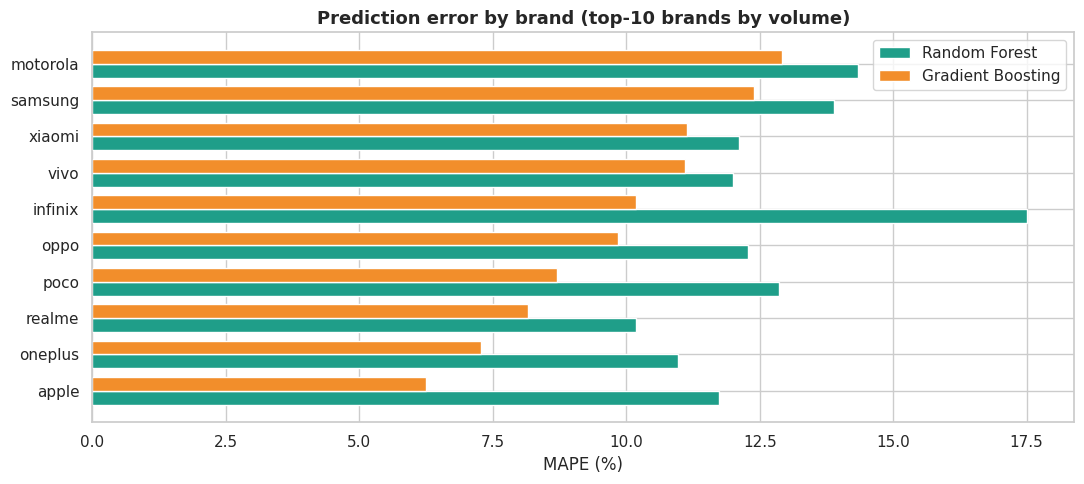

In [26]:
top10 = data["brand"].value_counts().head(10).index
bb = oof[oof.brand.isin(top10)].groupby("brand")[["ape_RF", "ape_GB"]].mean().sort_values("ape_GB")

fig, ax = plt.subplots(figsize=(11, 5))
y_pos = np.arange(len(bb)); h = .38
ax.barh(y_pos - h/2, bb["ape_RF"], h, color=RF_C, label="Random Forest")
ax.barh(y_pos + h/2, bb["ape_GB"], h, color=GB_C, label="Gradient Boosting")
ax.set_yticks(y_pos); ax.set_yticklabels(bb.index); ax.set_xlabel("MAPE (%)"); ax.legend()
ax.set_title("Prediction error by brand (top-10 brands by volume)")
plt.tight_layout(); plt.show()

In [27]:
# Value-for-money: model says "specs are worth X" — compare with real price (uses whichever model has lower OOF MAE)
use = "GB" if oof["ae_GB"].mean() <= oof["ae_RF"].mean() else "RF"
print(f"Using {'Gradient Boosting' if use=='GB' else 'Random Forest'} out-of-fold predictions (lower overall error)")
oof["fair_price"] = oof[f"pred_{use}"].round(-2)
oof["gap_%"] = ((oof["price"] - oof["fair_price"]) / oof["fair_price"] * 100).round(1)

cols = ["brand", "model", "price", "fair_price", "gap_%"]
print("\n💎 Best value — priced well BELOW what their specs suggest:")
display(oof.sort_values("gap_%").head(8)[cols].reset_index(drop=True))
print("💸 Premium-priced — priced well ABOVE what their specs suggest (brand / design premium):")
display(oof.sort_values("gap_%", ascending=False).head(8)[cols].reset_index(drop=True))

Using Gradient Boosting out-of-fold predictions (lower overall error)

💎 Best value — priced well BELOW what their specs suggest:


,brand,model,price,fair_price,gap_%
0,motorola,Motorola Edge 20 Pro 5G,20750,37600.0,-44.8
1,samsung,Samsung Galaxy F05,6499,11500.0,-43.5
2,nothing,Nothing Phone 3 (16GB RAM + 512GB),54999,93300.0,-41.1
3,tecno,Tecno Spark Go 5G,9999,16500.0,-39.4
4,samsung,Samsung Galaxy F16 5G (8GB RAM + 128GB),15499,24500.0,-36.7
5,motorola,Motorola Edge 60 Stylus,20560,32400.0,-36.5
6,samsung,Samsung Galaxy F16 5G,12499,19400.0,-35.6
7,vivo,Vivo Y28e 5G (4GB RAM + 64GB),9999,15500.0,-35.5


💸 Premium-priced — priced well ABOVE what their specs suggest (brand / design premium):


,brand,model,price,fair_price,gap_%
0,realme,Realme C63 5G,24999,12800.0,95.3
1,nothing,Nothing Phone 3 5G,79999,45300.0,76.6
2,oppo,OPPO Find X9 Ultra,169999,96300.0,76.5
3,vivo,Vivo V60 5G,50302,28700.0,75.3
4,samsung,Samsung Galaxy Note 20 Ultra 5G,116000,66800.0,73.7
5,samsung,Samsung Galaxy Z Fold 5 (12GB RAM + 512GB),164999,99800.0,65.3
6,google,Google Pixel 9 Pro,109999,67700.0,62.5
7,samsung,Samsung Galaxy Z Fold 5,154999,96700.0,60.3


## 7️⃣ Bonus — price-**segment classification** (Random Forest vs Gradient Boosting)

Same features, but now predicting the *class*: **Budget (<₹15k) · Mid (₹15–30k) · Upper-mid (₹30–60k) · Flagship (>₹60k)**.

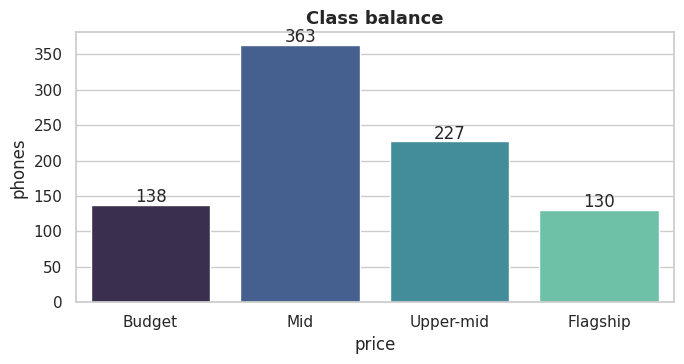

🌲 RF  best CV macro-F1 = 0.817   params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}
🚀 GB  best CV macro-F1 = 0.818   params: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': 4, 'learning_rate': 0.06}


In [28]:
labels = ["Budget", "Mid", "Upper-mid", "Flagship"]
y_cls = pd.cut(y, [0, 15000, 30000, 60000, np.inf], labels=labels)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_cls, test_size=.2, random_state=RANDOM_STATE, stratify=y_cls)

fig, ax = plt.subplots(figsize=(7, 3.8))
vc = y_cls.value_counts().reindex(labels)
sns.barplot(x=vc.index, y=vc.values, palette="mako", ax=ax)
for i, v in enumerate(vc.values): ax.text(i, v + 4, str(v), ha="center")
ax.set_title("Class balance"); ax.set_ylabel("phones")
plt.tight_layout(); plt.show()

def make_clf(est): return Pipeline([("prep", preprocessor), ("model", est)])
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

rf_c_search = RandomizedSearchCV(make_clf(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 8, 12, 20], "model__min_samples_leaf": [1, 2, 4],
     "model__max_features": ["sqrt", 0.4, 0.7], "model__class_weight": [None, "balanced"]},
    n_iter=12, cv=skf, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=1).fit(Xc_train, yc_train)

gb_c_search = RandomizedSearchCV(make_clf(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.06, 0.1, 0.15], "model__max_depth": [2, 3, 4],
     "model__subsample": [0.7, 0.9, 1.0], "model__min_samples_leaf": [1, 3, 6]},
    n_iter=12, cv=skf, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1).fit(Xc_train, yc_train)

rf_clf, gb_clf = rf_c_search.best_estimator_, gb_c_search.best_estimator_
print(f"🌲 RF  best CV macro-F1 = {rf_c_search.best_score_:.3f}   params: { {k.split('__')[1]: v for k, v in rf_c_search.best_params_.items()} }")
print(f"🚀 GB  best CV macro-F1 = {gb_c_search.best_score_:.3f}   params: { {k.split('__')[1]: v for k, v in gb_c_search.best_params_.items()} }")

,Accuracy,Balanced acc.,Macro F1,Weighted F1,MCC
Model,,,,,
Random Forest,0.866,0.877,0.867,0.865,0.812
Gradient Boosting,0.808,0.799,0.804,0.806,0.725



──────── Random Forest ────────
              precision    recall  f1-score   support

      Budget      0.806     0.893     0.847        28
         Mid      0.877     0.877     0.877        73
   Upper-mid      0.897     0.778     0.833        45
    Flagship      0.862     0.962     0.909        26

    accuracy                          0.866       172
   macro avg      0.861     0.877     0.867       172
weighted avg      0.868     0.866     0.865       172


──────── Gradient Boosting ────────
              precision    recall  f1-score   support

      Budget      0.821     0.821     0.821        28
         Mid      0.810     0.877     0.842        73
   Upper-mid      0.775     0.689     0.729        45
    Flagship      0.840     0.808     0.824        26

    accuracy                          0.808       172
   macro avg      0.812     0.799     0.804       172
weighted avg      0.807     0.808     0.806       172



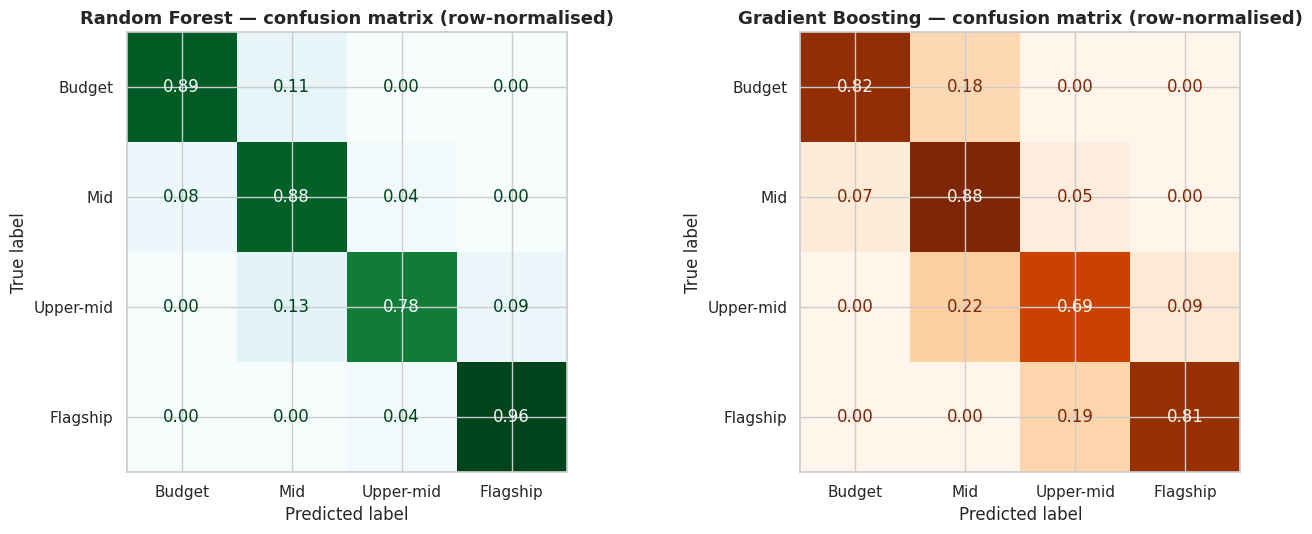

In [29]:
clf_preds = {"Random Forest": rf_clf.predict(Xc_test), "Gradient Boosting": gb_clf.predict(Xc_test)}

clf_rows = []
for n, p in clf_preds.items():
    clf_rows.append({"Model": n, "Accuracy": accuracy_score(yc_test, p), "Balanced acc.": balanced_accuracy_score(yc_test, p),
                     "Macro F1": f1_score(yc_test, p, average="macro"), "Weighted F1": f1_score(yc_test, p, average="weighted"),
                     "MCC": matthews_corrcoef(yc_test, p)})
clf_results = pd.DataFrame(clf_rows).set_index("Model")
display(clf_results.round(3))

for n, p in clf_preds.items():
    print(f"\n──────── {n} ────────")
    print(classification_report(yc_test, p, labels=labels, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (n, p), cmap in zip(axes, clf_preds.items(), ["BuGn", "Oranges"]):
    ConfusionMatrixDisplay.from_predictions(yc_test, p, labels=labels, normalize="true", cmap=cmap, ax=ax, values_format=".2f", colorbar=False)
    ax.set_title(f"{n} — confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()

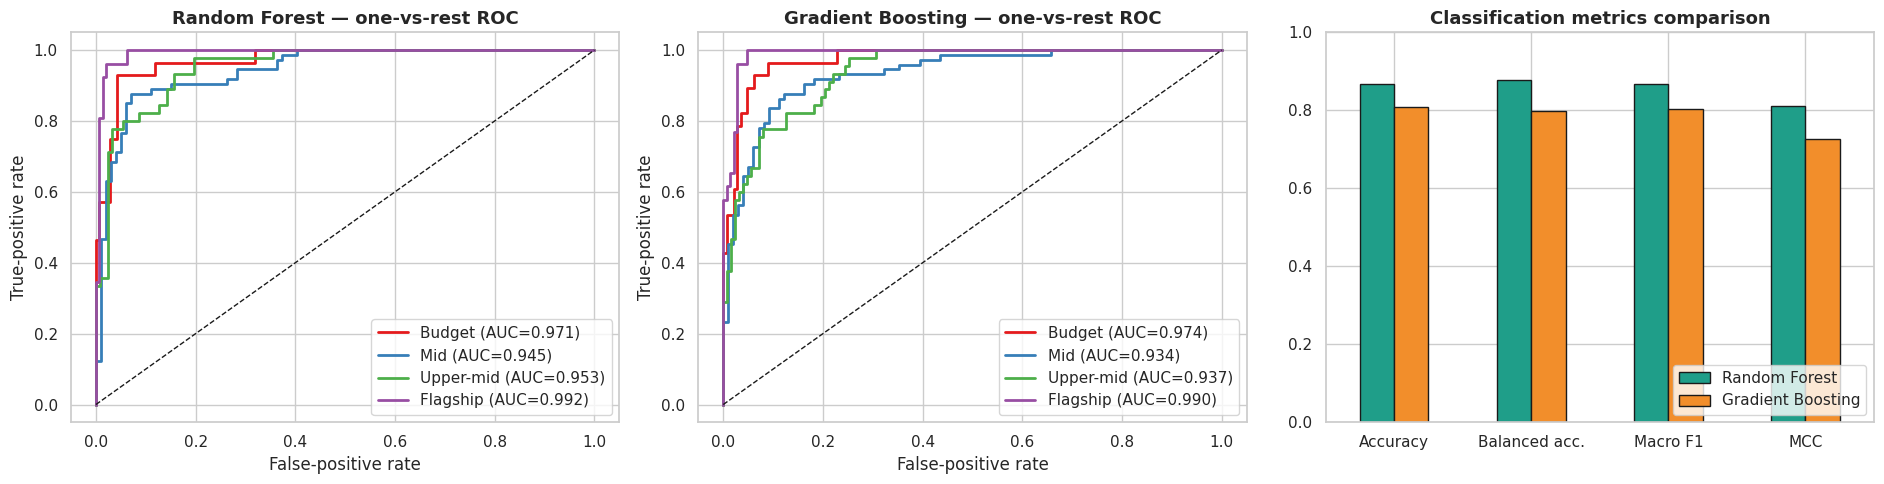

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
Y_bin = label_binarize(yc_test, classes=labels)
palette = sns.color_palette("Set1", 4)
for ax, (n, clf) in zip(axes[:2], [("Random Forest", rf_clf), ("Gradient Boosting", gb_clf)]):
    proba = clf.predict_proba(Xc_test)
    classes = list(clf.classes_)
    for i, lab in enumerate(labels):
        fpr, tpr, _ = roc_curve(Y_bin[:, i], proba[:, classes.index(lab)])
        ax.plot(fpr, tpr, lw=2, color=palette[i], label=f"{lab} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"{n} — one-vs-rest ROC"); ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate"); ax.legend(loc="lower right")

clf_results[["Accuracy", "Balanced acc.", "Macro F1", "MCC"]].T.plot(kind="bar", color=[RF_C, GB_C], ax=axes[2], rot=0, edgecolor="k")
axes[2].set_title("Classification metrics comparison"); axes[2].set_ylim(0, 1); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8️⃣ Final comparison, prediction demo & saving

,Random Forest,Gradient Boosting,Winner
Test MAE (₹),5536.515,3886.843,Gradient Boosting
Test RMSE (₹),11554.883,8088.431,Gradient Boosting
Test MAPE (%),13.539,10.751,Gradient Boosting
Test R²,0.879,0.941,Gradient Boosting
Test R² (log price),0.936,0.956,Gradient Boosting
10-fold CV R²,0.917,0.940,Gradient Boosting
Segment accuracy,0.866,0.808,Random Forest
Segment macro-F1,0.867,0.804,Random Forest


Winner
Gradient Boosting    6
Random Forest        2


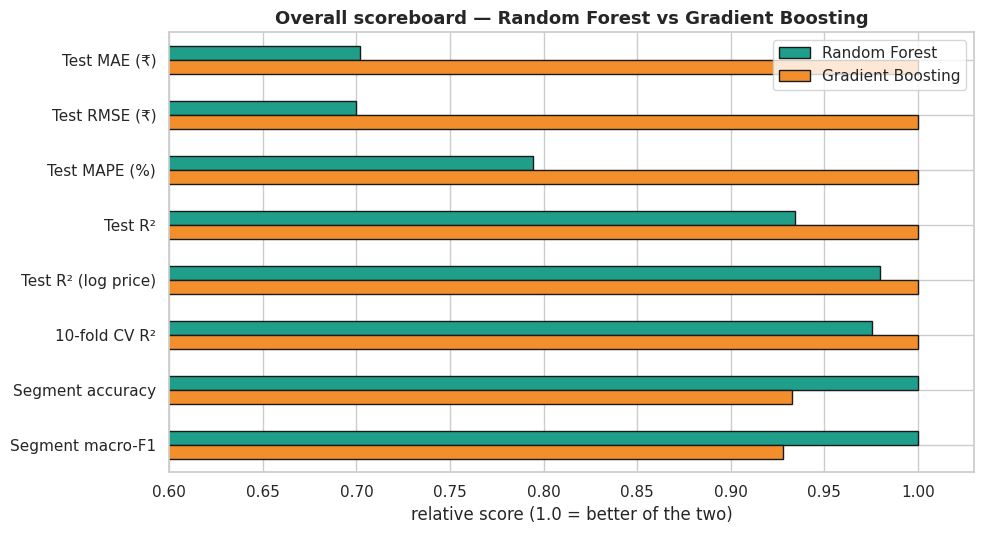

In [31]:
summary = pd.DataFrame({
    "Random Forest": [results.loc["RF (tuned)", "MAE (₹)"], results.loc["RF (tuned)", "RMSE (₹)"], results.loc["RF (tuned)", "MAPE (%)"],
                      results.loc["RF (tuned)", "R²"], results.loc["RF (tuned)", "R² (log)"], cv_scores["Random Forest"].mean(),
                      clf_results.loc["Random Forest", "Accuracy"], clf_results.loc["Random Forest", "Macro F1"]],
    "Gradient Boosting": [results.loc["GB (tuned)", "MAE (₹)"], results.loc["GB (tuned)", "RMSE (₹)"], results.loc["GB (tuned)", "MAPE (%)"],
                          results.loc["GB (tuned)", "R²"], results.loc["GB (tuned)", "R² (log)"], cv_scores["Gradient Boosting"].mean(),
                          clf_results.loc["Gradient Boosting", "Accuracy"], clf_results.loc["Gradient Boosting", "Macro F1"]],
}, index=["Test MAE (₹)", "Test RMSE (₹)", "Test MAPE (%)", "Test R²", "Test R² (log price)", "10-fold CV R²", "Segment accuracy", "Segment macro-F1"])

lower_better = {"Test MAE (₹)", "Test RMSE (₹)", "Test MAPE (%)"}
summary["Winner"] = [("Random Forest" if (r["Random Forest"] < r["Gradient Boosting"]) == (i in lower_better) else "Gradient Boosting")
                     for i, r in summary.iterrows()]
display(summary.round(3))
print(summary["Winner"].value_counts().to_string())

# overall scoreboard figure (normalised so that 1 = best)
norm = pd.DataFrame(index=summary.index)
for c in ["Random Forest", "Gradient Boosting"]:
    norm[c] = [(summary.loc[i, c] / summary.loc[i, ["Random Forest", "Gradient Boosting"]].max()) if i not in lower_better
               else (summary.loc[i, ["Random Forest", "Gradient Boosting"]].min() / summary.loc[i, c]) for i in summary.index]
ax = norm.plot(kind="barh", color=[RF_C, GB_C], figsize=(10, 5.5), edgecolor="k")
ax.set_xlim(.6, 1.03); ax.invert_yaxis(); ax.set_xlabel("relative score (1.0 = better of the two)")
ax.set_title("Overall scoreboard — Random Forest vs Gradient Boosting")
plt.tight_layout(); plt.show()

In [32]:
# 🔮 Predict the price of a brand-new phone with BOTH models
new_phone = pd.DataFrame([{
    "brand": "samsung", "model": "Hypothetical Galaxy X", "processor_name": "Snapdragon 8 Gen 3", "core": 8, "processor_speed": 3.3,
    "ram_size": 12, "internal_memory": 256, "battery_capacity": 5000, "max_chrg_pwr": 45, "screen_size": 6.7,
    "resolution": "1440 x 3120", "refresh_rate": 120, "screen_spec": "Punch Hole", "back_camera": 200, "front_camera": 12,
    "no_of_rear": 4, "no_of_front": 1, "os": "Android", "os_version": 15.0, "extend_upto": np.nan,
    "is_dual_sim": True, "is_5G": True, "is_irBlaster": False, "is_nfc": True, "is_eSim": True,
    "fast_charging": True, "extended_memory_available": False}])
nx = engineer(new_phone)[FEATURES]
p_rf, p_gb = rf_best.predict(nx)[0], gb_best.predict(nx)[0]
print(f"🌲 Random Forest predicts      ₹{p_rf:,.0f}")
print(f"🚀 Gradient Boosting predicts  ₹{p_gb:,.0f}")
print(f"   average of the two          ₹{(p_rf + p_gb) / 2:,.0f}")

# rough uncertainty: spread of individual trees in the Random Forest
rf_inner = rf_best.regressor_.named_steps["model"]
tree_preds = np.expm1(np.array([t.predict(rf_best.regressor_.named_steps["prep"].transform(nx)) for t in rf_inner.estimators_]).ravel())
lo, hi = np.percentile(tree_preds, [10, 90])
print(f"   RF 80% tree-spread range    ₹{lo:,.0f} – ₹{hi:,.0f}")

🌲 Random Forest predicts      ₹83,044
🚀 Gradient Boosting predicts  ₹83,655
   average of the two          ₹83,350


   RF 80% tree-spread range    ₹55,999 – ₹119,999


In [33]:
os.makedirs("saved_models", exist_ok=True)
joblib.dump(rf_best, "saved_models/rf_price_regressor.joblib")
joblib.dump(gb_best, "saved_models/gb_price_regressor.joblib")
joblib.dump(rf_clf, "saved_models/rf_segment_classifier.joblib")
joblib.dump(gb_clf, "saved_models/gb_segment_classifier.joblib")
results.round(3).to_csv("saved_models/regression_test_metrics.csv")
oof[["brand", "model", "price", "pred_RF", "pred_GB", "gap_%"]].to_csv("saved_models/out_of_fold_predictions.csv", index=False)
print("Saved:", *sorted(os.listdir("saved_models")), sep="\n  • ")
print("\nReload later with:  joblib.load('saved_models/gb_price_regressor.joblib').predict(engineer(new_df)[FEATURES])")

Saved:
  • gb_price_regressor.joblib
  • gb_segment_classifier.joblib
  • out_of_fold_predictions.csv
  • regression_test_metrics.csv
  • rf_price_regressor.joblib
  • rf_segment_classifier.joblib

Reload later with:  joblib.load('saved_models/gb_price_regressor.joblib').predict(engineer(new_df)[FEATURES])


## 9️⃣ Conclusions

**Price prediction (regression, held-out test set of 172 phones)**

| Metric | 🌲 Random Forest (tuned) | 🚀 Gradient Boosting (tuned) |
|---|---|---|
| MAE | ₹5,537 | **₹3,887** |
| RMSE | ₹11,555 | **₹8,088** |
| MAPE | 13.5 % | **10.8 %** |
| R² | 0.879 | **0.941** |
| 10-fold CV R² | 0.917 | **0.940** |

* **Gradient Boosting wins the price-prediction task** on every regression metric, both on the test set and in cross-validation (paired t-test on fold MAE is significant). Tuning improved GB more (test MAE ₹4,430 → ₹3,887) than RF (₹5,790 → ₹5,537).
* Both models over-fit a bit (train R² ≈ 0.99 vs test 0.88–0.94) — normal for tree ensembles on only 858 rows. The learning curves show validation error still falling, so **more data would help**.
* **Error is largest for flagships** (MAE ≈ ₹13k for GB vs ≈ ₹1.5k for budget phones), but relative error (MAPE) is similar across segments: roughly 8–15 %.
* The most useful signals are RAM, storage, display resolution/pixel density (`megapixels`, `ppi`, `res_w`) and processor speed. Battery capacity looks non-monotonic in the partial-dependence plot because flagships (e.g. iPhones) have *smaller* batteries but cost far more — a confounding effect, not a causal one.
* Brand and design premium are things specs cannot capture: the model flags phones such as Nothing Phone 3, OPPO Find X9 Ultra and the Galaxy Z Fold 5 as priced well above their spec-implied value.

**Segment classification (bonus)** — here **Random Forest wins**: accuracy 86.6 % vs 80.8 %, macro-F1 0.867 vs 0.804. Most mistakes are between neighbouring segments (Mid ↔ Upper-mid), which is expected near price boundaries.

**Takeaway:** use **Gradient Boosting for predicting the exact price**, and Random Forest is a strong, more robust choice when you only need the price *tier*.

**Limitations / next steps:** small dataset; `rating` was excluded on purpose; no launch-year or brand-popularity feature; prices are a single snapshot. Ideas: add release date, text features from the model name, and monotonic constraints for RAM/storage.